# Core plotting functions

### Aim:
Scanpy's main plotting tools and when to use each

Part 1: Scatter plots on embeddings (UMAP, t-SNE): colouring cells by genes or annotations
Part 2: Identifying clusters with known marker genes: dotplots, violin plots, heatmaps and similar
Part 3: Visualising differentially expressed genes: plotting the results of rank_genes_groups

### Data:
pbmc68k_reduced - 700-cell query datatset from the integration notebook. Already processed with PCA, a neighbour graph and UMAP computed. 

### Literature markers:
new gene name inside ()
| cell type | marker | what the gene does|
|---|---|---|
|B cell| CD79A, MS4A1 (CD20) | parts of the B-cell receptor, CD20 is the target of rituximab|
|Plasma cell| IGJ (JCHAIN) | joins antibody molecules together |
| T cell | CD3D | part of the T-cell receptor complex|
|NK | GNLY, NKG7 | cell-killing machinery|
|Myeloid | CST3, LYZ | generali myeloid genes (LYZ=lysozyme, an antibacterial enzyme)|
|Monocytes | FCGR3A (CD16) | markes the non-classical monocytes from before |
| Dendritic | FCER1A | an antibody receptor, high on dendritic cells |

In [2]:
from __future__ import annotations
import scanpy as sc
from matplotlib.pyplot import rc_context

sc.set_figure_params(dpi=100, color_map="viridis_r") 
# color map viridis_r set colour scale for continuous values

sc.settings.verbosity = 0 # shows error messages only not progress bars or info messages
sc.logging.print_header()

/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/IPython/core/formatters.py:1035: RuntimeWarning: Failed to import dependencies for application/vnd.jupyter.widget-view+json representation. (ModuleNotFoundError: No module named 'ipywidgets')
  return method(include=include, exclude=exclude)


Package,Version
scanpy,1.12.4
matplotlib,3.11.2
Component,Info
Python,"3.12.8 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 10:37:40) [Clang 14.0.6 ]"
OS,macOS-15.3.1-arm64-arm-64bit
CPU,"8/8 logical CPU cores, arm"
GPU,No GPU found
Updated,2026-10-18 15:24
Dependency,Version
fast-array-utils,1.5.1


In [3]:
pbmc = sc.datasets.pbmc68k_reduced()
pbmc

# obs - per-cell info
# var - per-gene stats
# uns - results of earlier steps
# obsm - per-cell matrices
# varm - PCA gene weights
# obsp - the neighbour graph

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
    var: 'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

## Visualization of gene expression and other variables

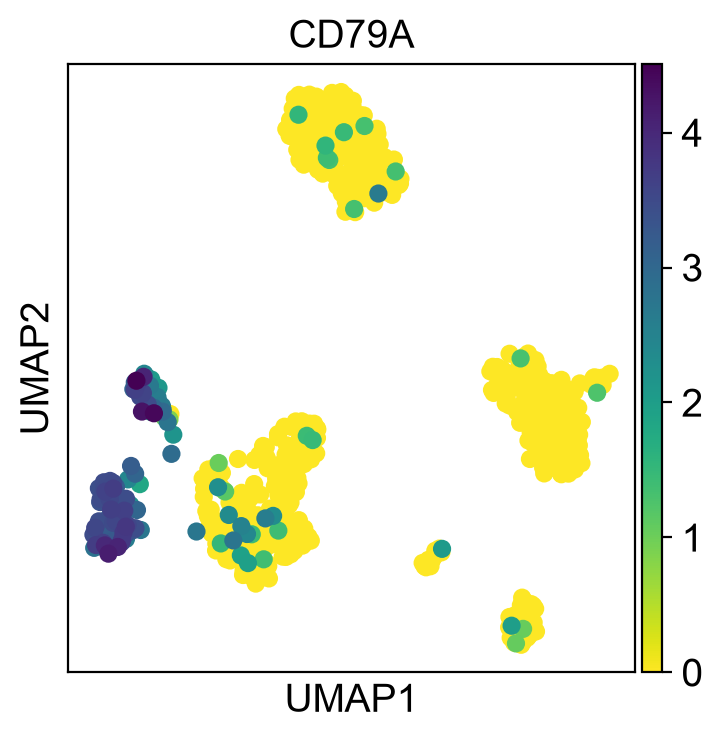

In [4]:
# Scatter plots: colouring the UMAP
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(pbmc, color="CD79A")

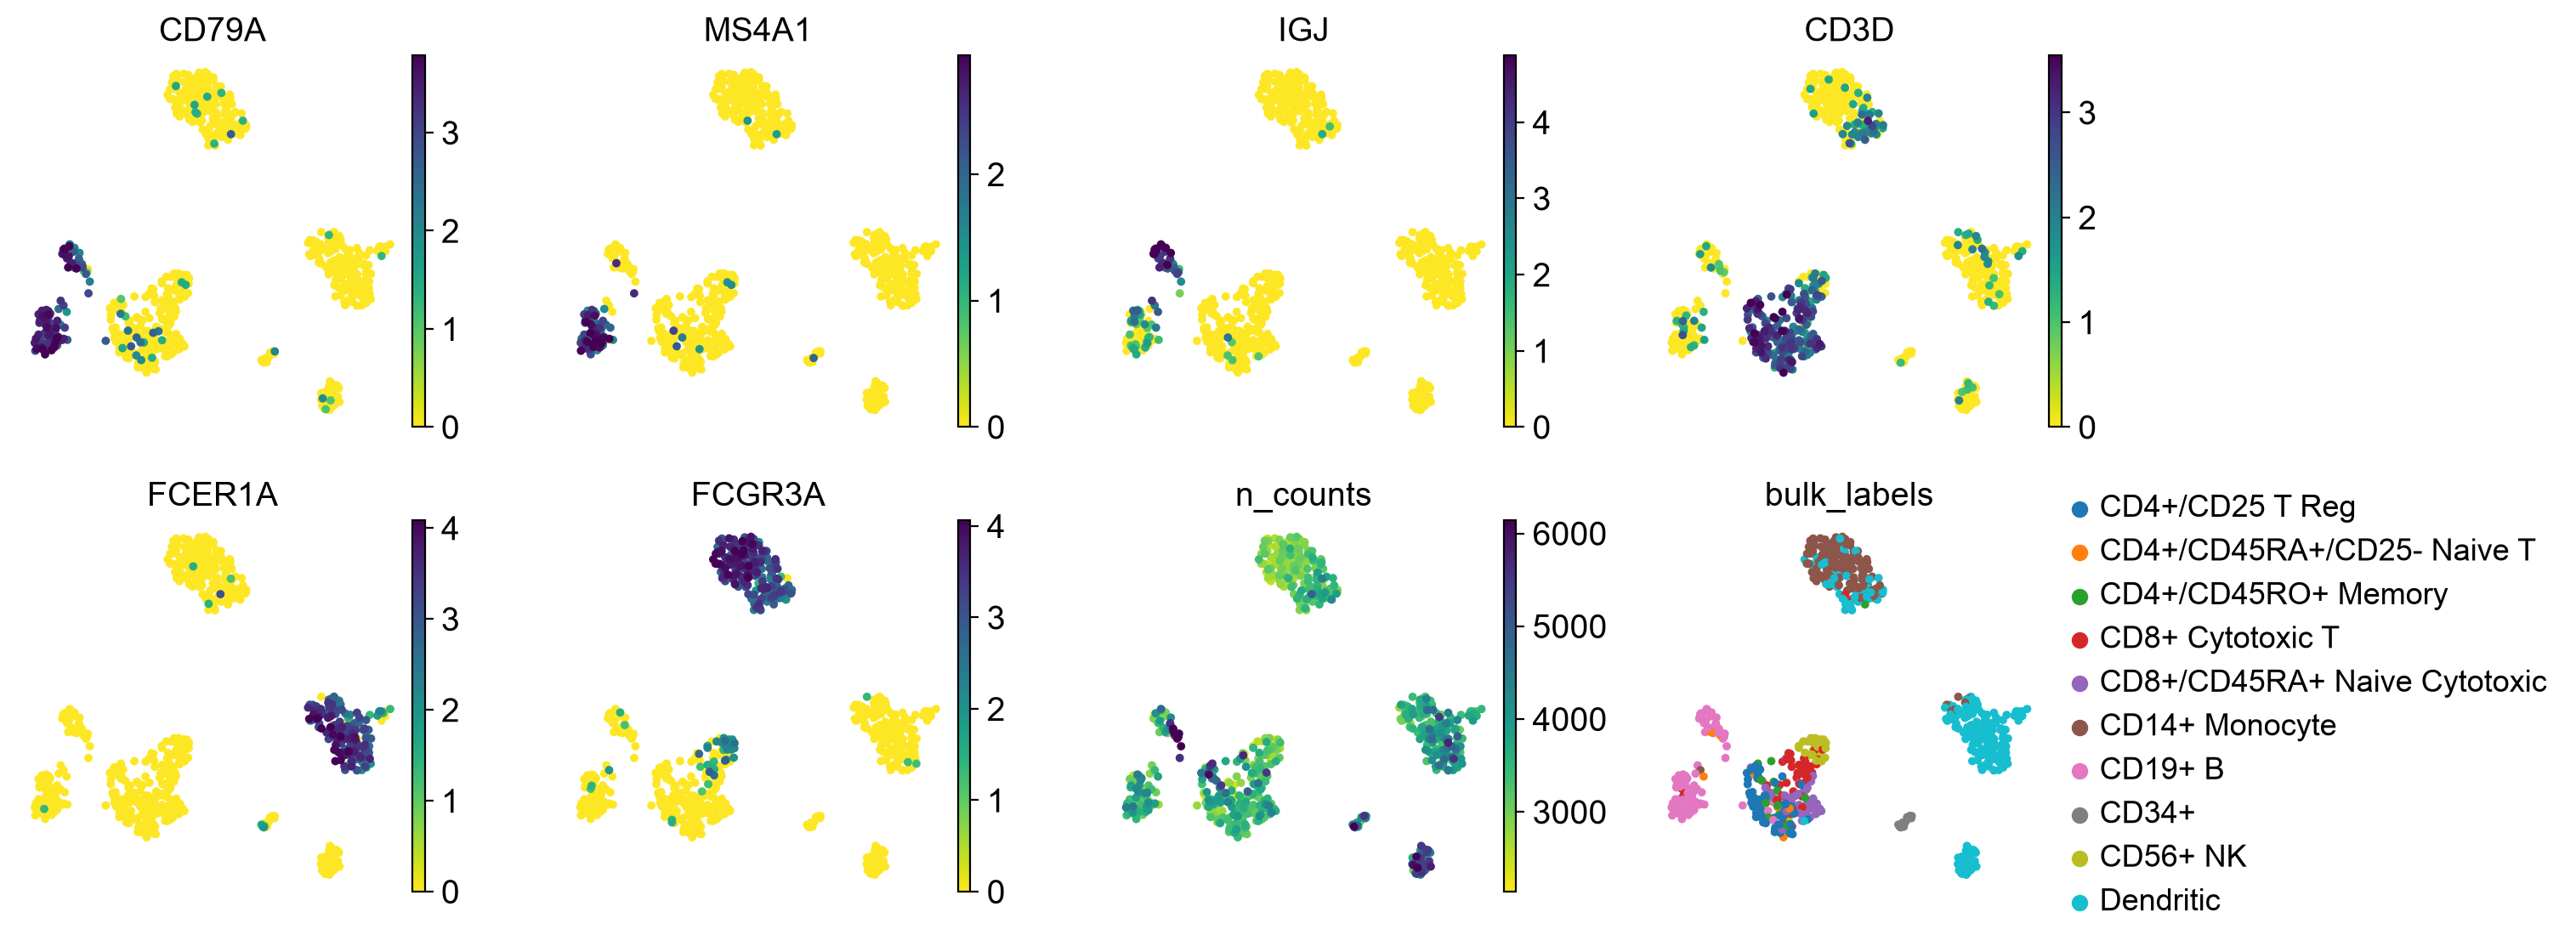

In [5]:
# plotting many variables at once
color_vars = [
    "CD79A", "MS4A1", "IGJ", "CD3D", "FCER1A", "FCGR3A",
    "n_counts",
    "bulk_labels",
]
with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(pbmc, color=color_vars, s=50, frameon=False, ncols=4, vmax="p99")

In [6]:
# compute clusters using the leiden method and store the results with the name `clusters`
sc.tl.leiden(
    pbmc,
    key_added="clusters",
    resolution=0.5,
    n_iterations=2,
    flavor="igraph",
    directed=False,
)

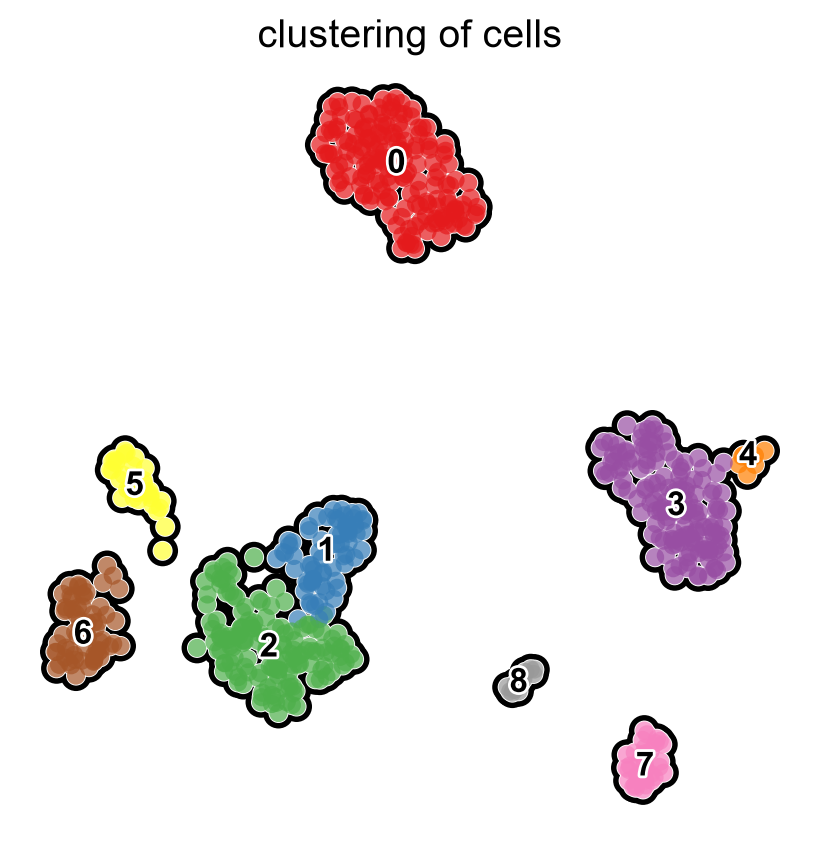

In [7]:
with rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(
        pbmc,
        color="clusters",
        add_outline=True,
        legend_loc="on data",
        legend_fontsize=12,
        legend_fontoutline=2,
        frameon=False,
        title="clustering of cells",
        palette="Set1",
    )

## Identification of clusters based on known marker genes

Turning numbered clusters into cell-type name using tracksplot like dotplots, violin plots, heatmaps

In [8]:
marker_genes_dict = {
    "B-cell": ["CD79A", "MS4A1"],
    "Dendritic": ["FCER1A", "CST3"],
    "Monocytes": ["FCGR3A"],
    "NK": ["GNLY", "NKG7"],
    "Other": ["IGLL1"],
    "Plasma": ["IGJ"],
    "T-cell": ["CD3D"],
}

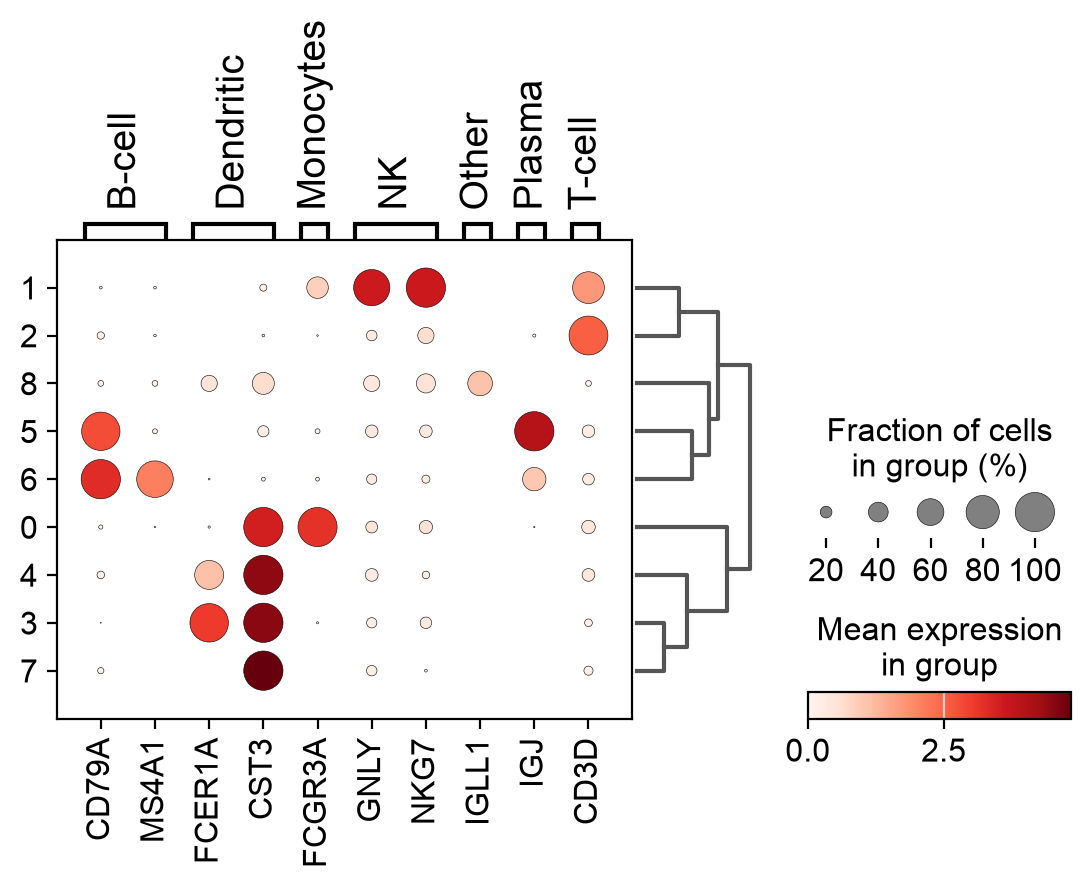

In [9]:
# dot plot
sc.pl.dotplot(pbmc, marker_genes_dict, "clusters", dendrogram=True)

# colour shows how high the gene's acerage expression is in that cluster
# size shows the fraction of cells in the cluster express it at all 
# dendrogram at the side put similar clusters next to each other 

In [10]:
# create a dictionary to map cluster to annotation label
cluster2annotation = {
    "0": "Monocytes",
    "1": "NK",
    "2": "T-cell",
    "3": "Dendritic",
    "4": "Dendritic",
    "5": "Plasma",
    "6": "B-cell",
    "7": "Dendritic",
    "8": "Other",
}

# add a new `.obs` column called `cell type` by mapping clusters to annotation using pandas `map` function
pbmc.obs["cell type"] = pbmc.obs["clusters"].map(cluster2annotation).astype("category")

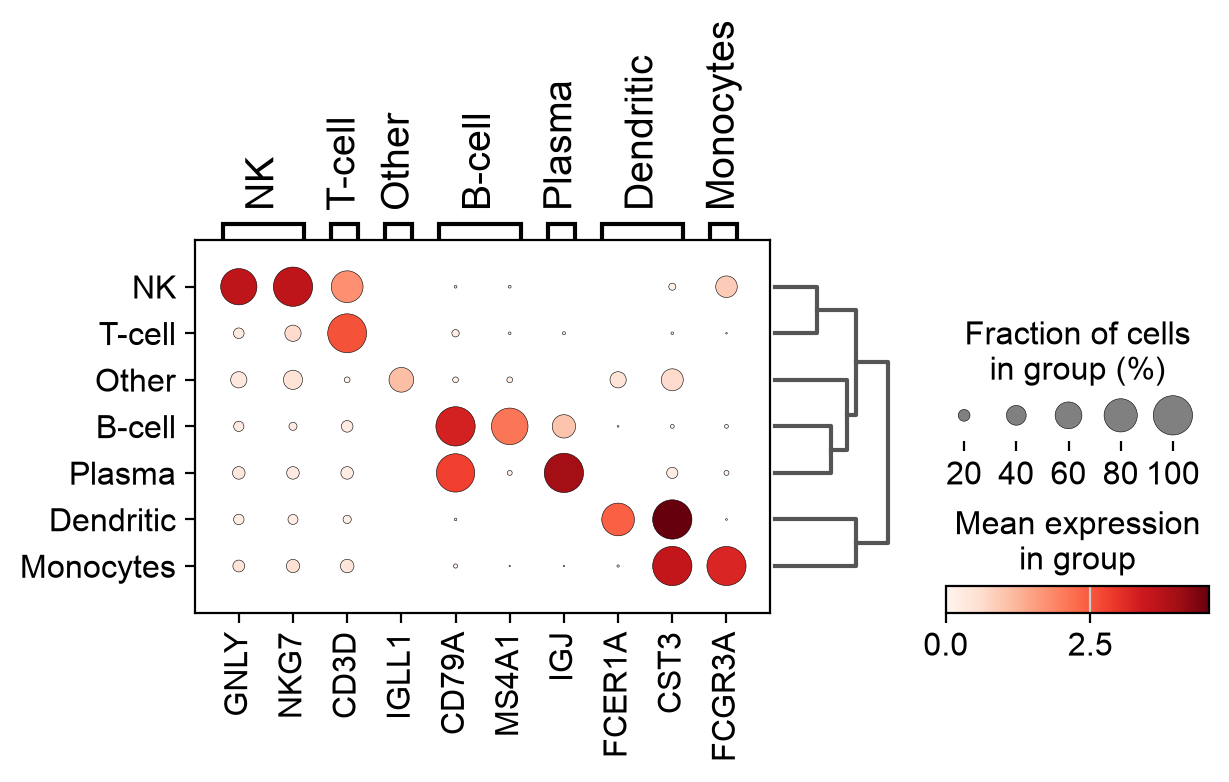

In [11]:
sc.pl.dotplot(pbmc, marker_genes_dict, "cell type", dendrogram=True)

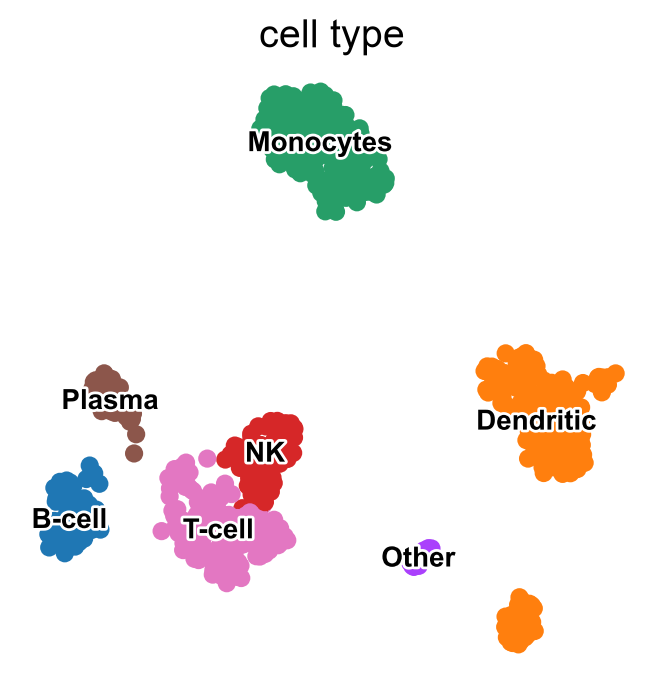

In [12]:
sc.pl.umap(
    pbmc,
    color="cell type",
    legend_loc="on data",
    frameon=False,
    legend_fontsize=10,
    legend_fontoutline=2,
)
# umap coloured bu cell type shows the lables formed sensible islands

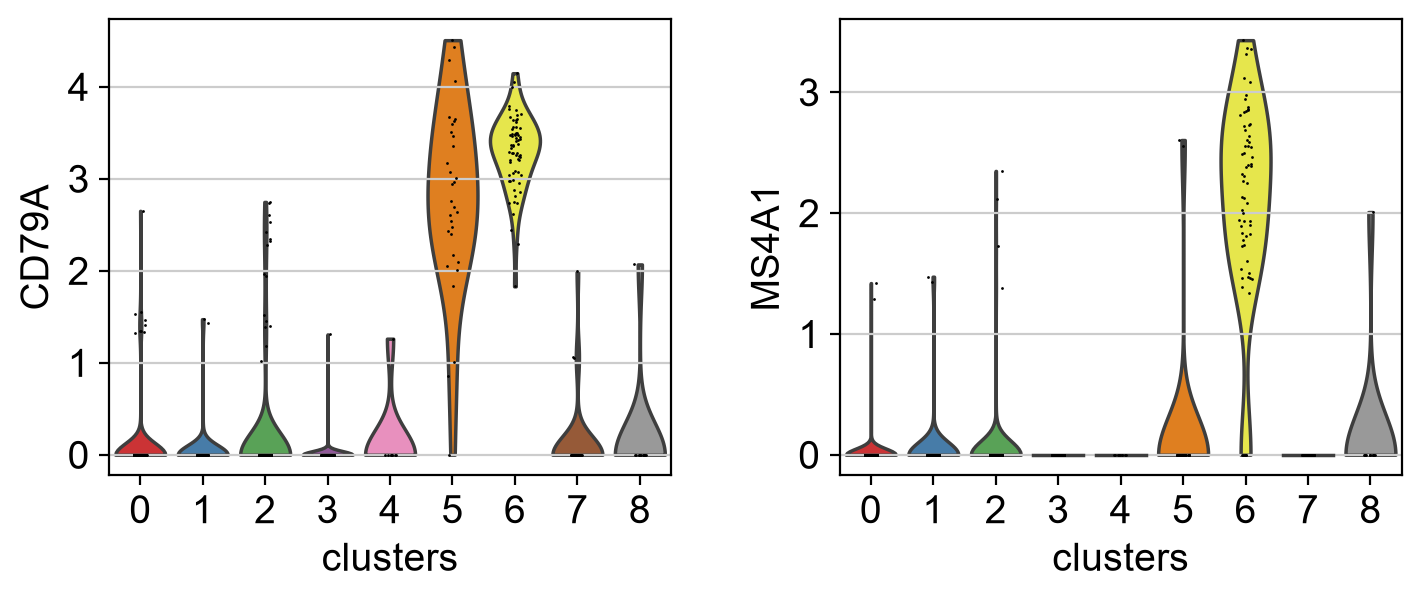

In [13]:
# violin plot
with rc_context({"figure.figsize": (4, 3)}):
    sc.pl.violin(pbmc, ["CD79A", "MS4A1"], groupby="clusters", dodge=False)

# dotplot shows average, violin plot shows whole distribution across cells in each cluster

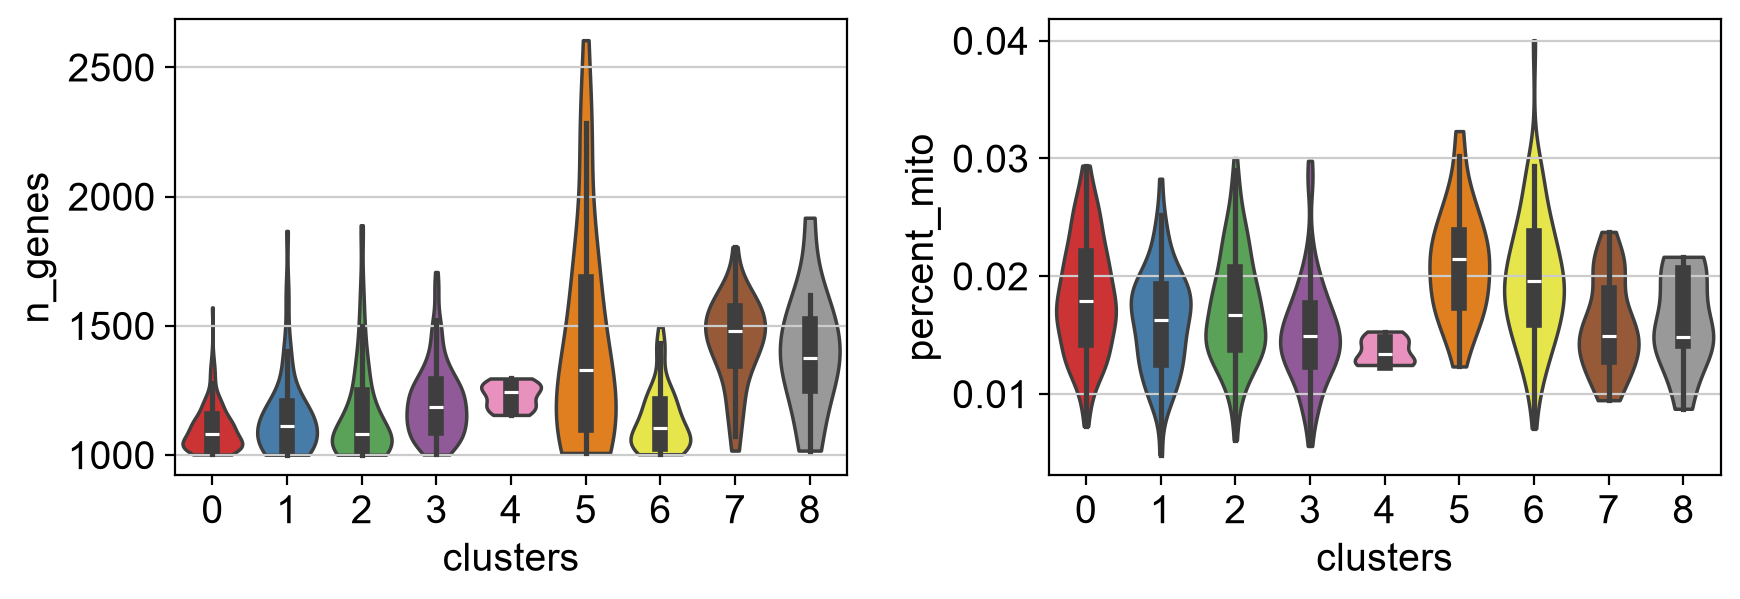

In [14]:
# quality checking plots to make sure no cluster is dominated by low-quality cells 
with rc_context({"figure.figsize": (4.5, 3)}):
    sc.pl.violin(
        pbmc,
        ["n_genes", "percent_mito"],
        groupby="clusters",
        stripplot=False,  # remove the internal dots
        inner="box",  # adds a boxplot inside violins
        dodge=False,
    )

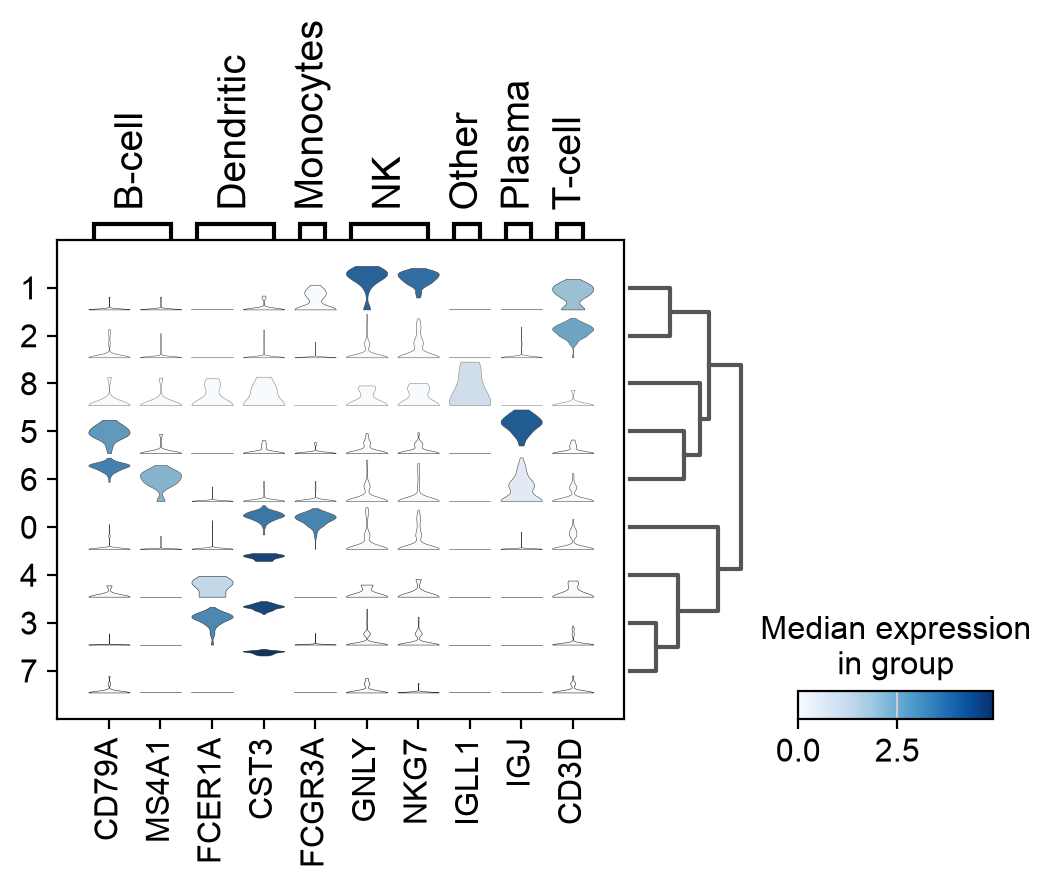

In [15]:
# stacked violin
ax = sc.pl.stacked_violin(pbmc, marker_genes_dict, groupby="clusters", swap_axes=False, dendrogram=True, dodge=False)

# IGJ is old gene name of JCHAIN
# FCGR3A is old gene name of CD16 that markes CD16+ monocytes and NK cells
# for monocytes, CD16, LYZ and CD14, for NK cells, CD16 and NKG7, GNLY to tell apart

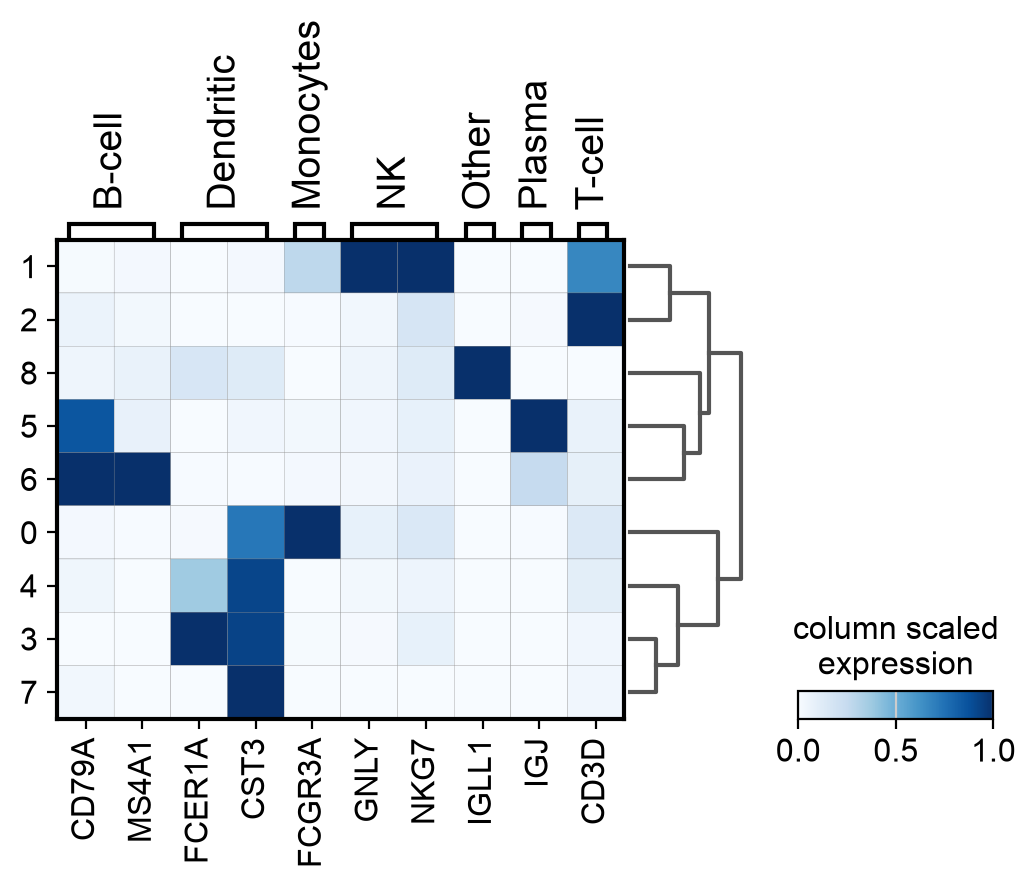

In [16]:
# matrix plot
# for visualising expression values per gene grouped by categories
sc.pl.matrixplot(
    pbmc,
    marker_genes_dict,
    "clusters",
    dendrogram=True,
    cmap="Blues",
    standard_scale="var",
    colorbar_title="column scaled\nexpression",
)

# similar to dotplot but without size, shows average expression of gene in that cluster

In [17]:
# normalize the gene expression 
# sc.pp.scale z-scored each gene 
# - how far a cell is above or below that gene's average in standard deviation (range -2 to 2)

pbmc.layers["scaled"] = sc.pp.scale(pbmc, copy=True).X
# this saves scaled values in a new layer called `scaled` so that we can use it for plotting without overwriting the original values inside AnnData object

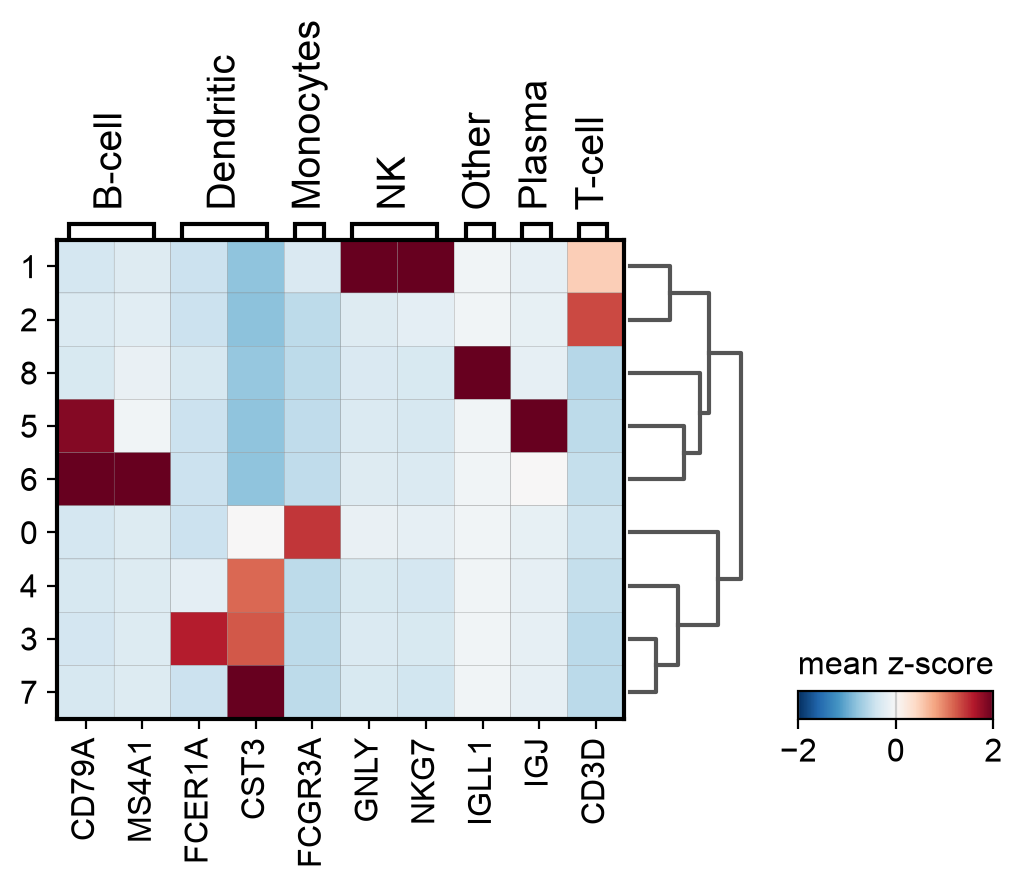

In [18]:
sc.pl.matrixplot(
    pbmc,
    marker_genes_dict,
    "clusters",
    dendrogram=True,
    colorbar_title="mean z-score",
    layer="scaled",
    vmin=-2,
    vmax=2, # set vmin/vmax to prevent few extreme values dont skew the colour scale
    cmap="RdBu_r",
)

## Multiple plots into subplots

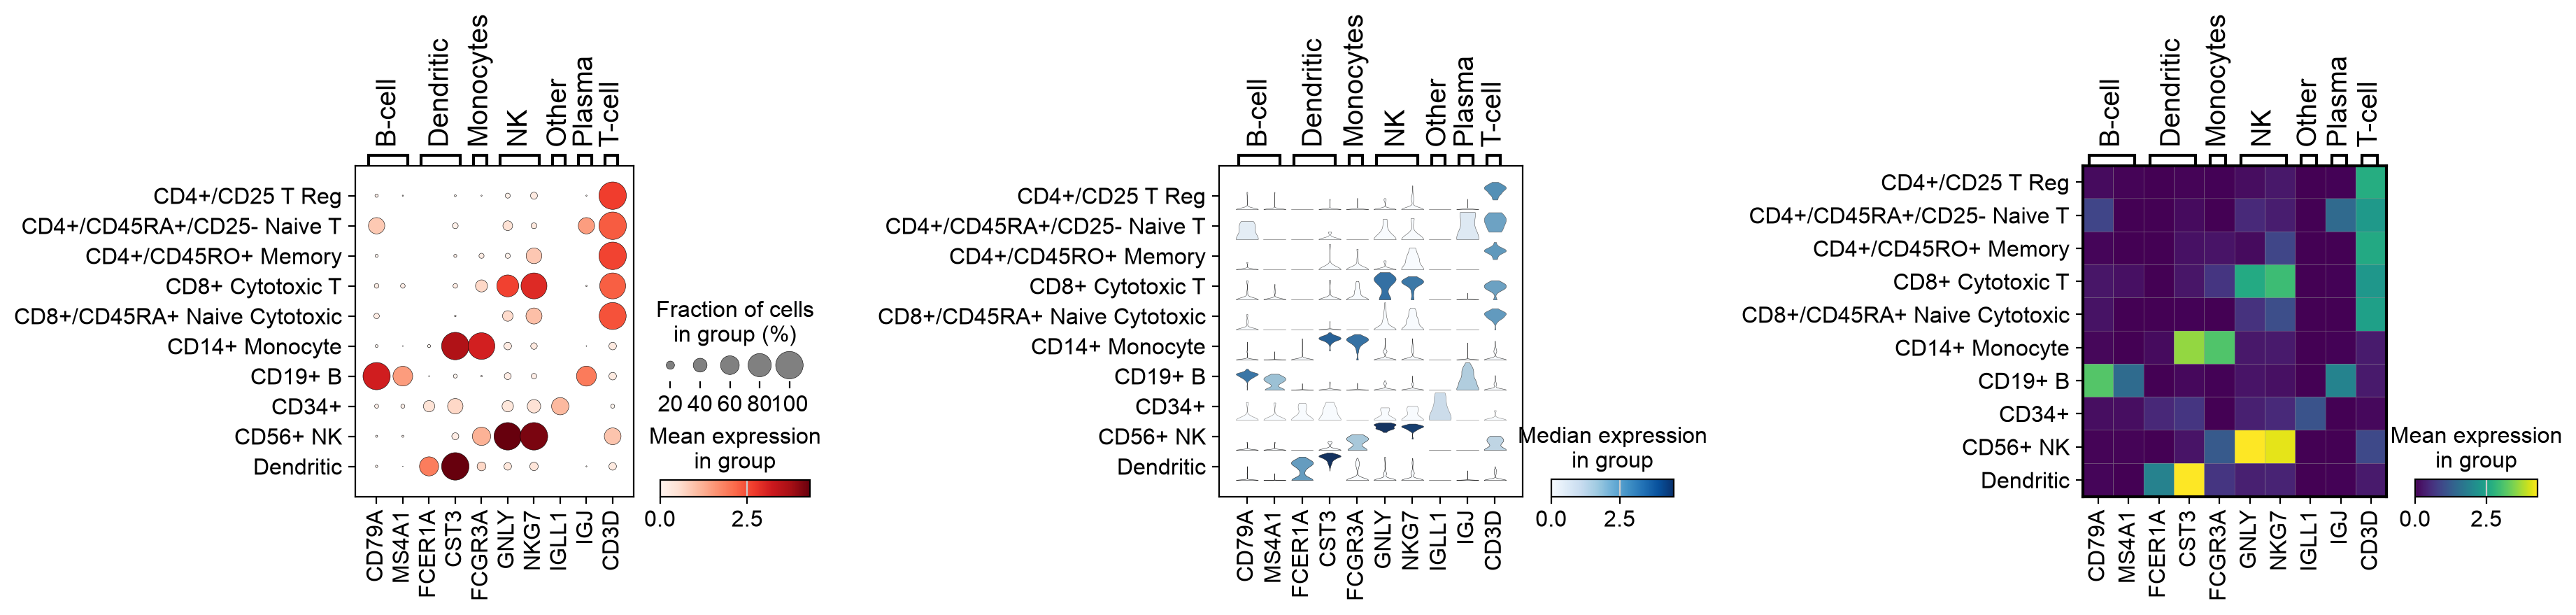

In [19]:
import matplotlib.pyplot as plt


fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 4), gridspec_kw={"wspace": 0.9})

ax1_dict = sc.pl.dotplot(pbmc, marker_genes_dict, groupby="bulk_labels", ax=ax1, show=False)
ax2_dict = sc.pl.stacked_violin(pbmc, marker_genes_dict, groupby="bulk_labels", ax=ax2, show=False, dodge=False)
ax3_dict = sc.pl.matrixplot(pbmc, marker_genes_dict, groupby="bulk_labels", ax=ax3, show=False, cmap="viridis")

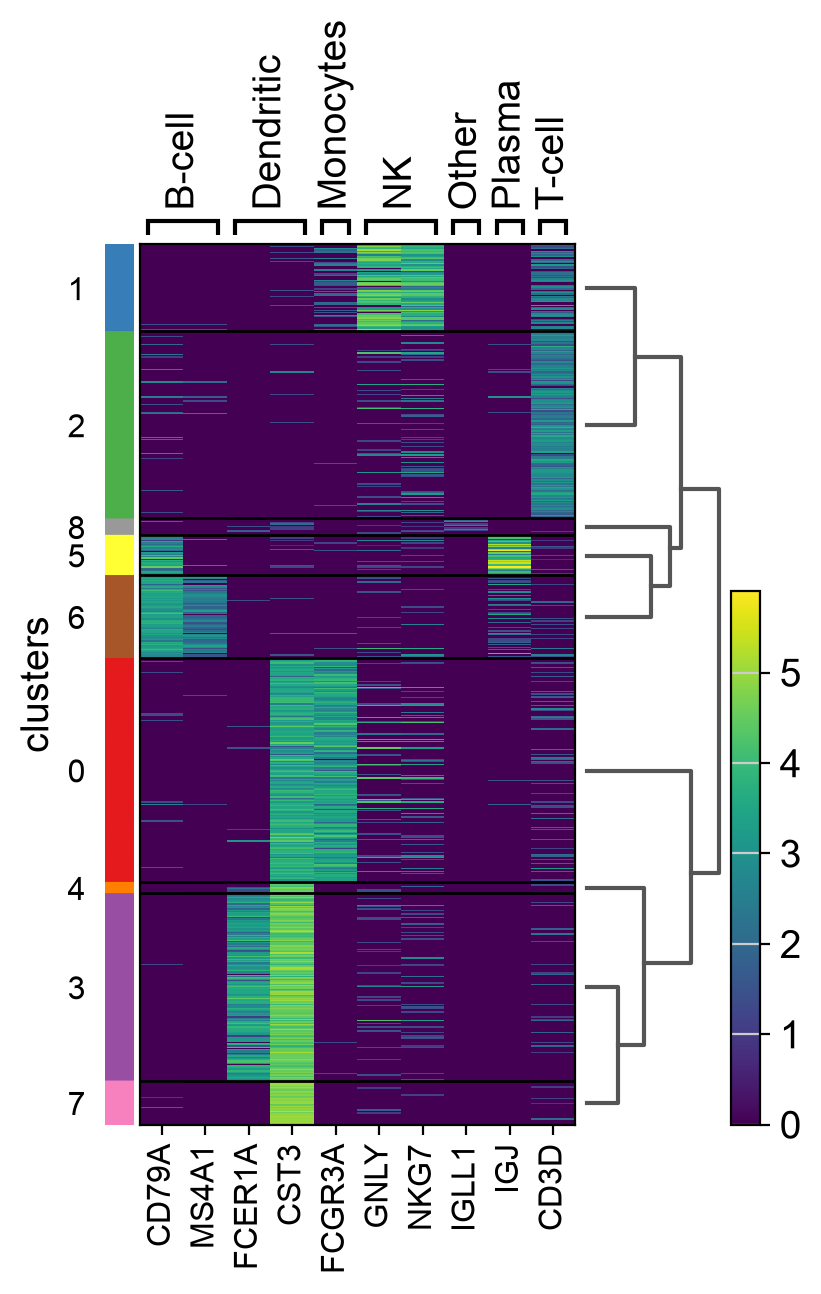

In [20]:
# Heatmap
# no average, each cell is its own line, grouped by cluster, dendrogram shows similar clusters next to each other
sc.pl.heatmap(pbmc, marker_genes_dict, groupby="clusters", cmap="viridis", dendrogram=True)

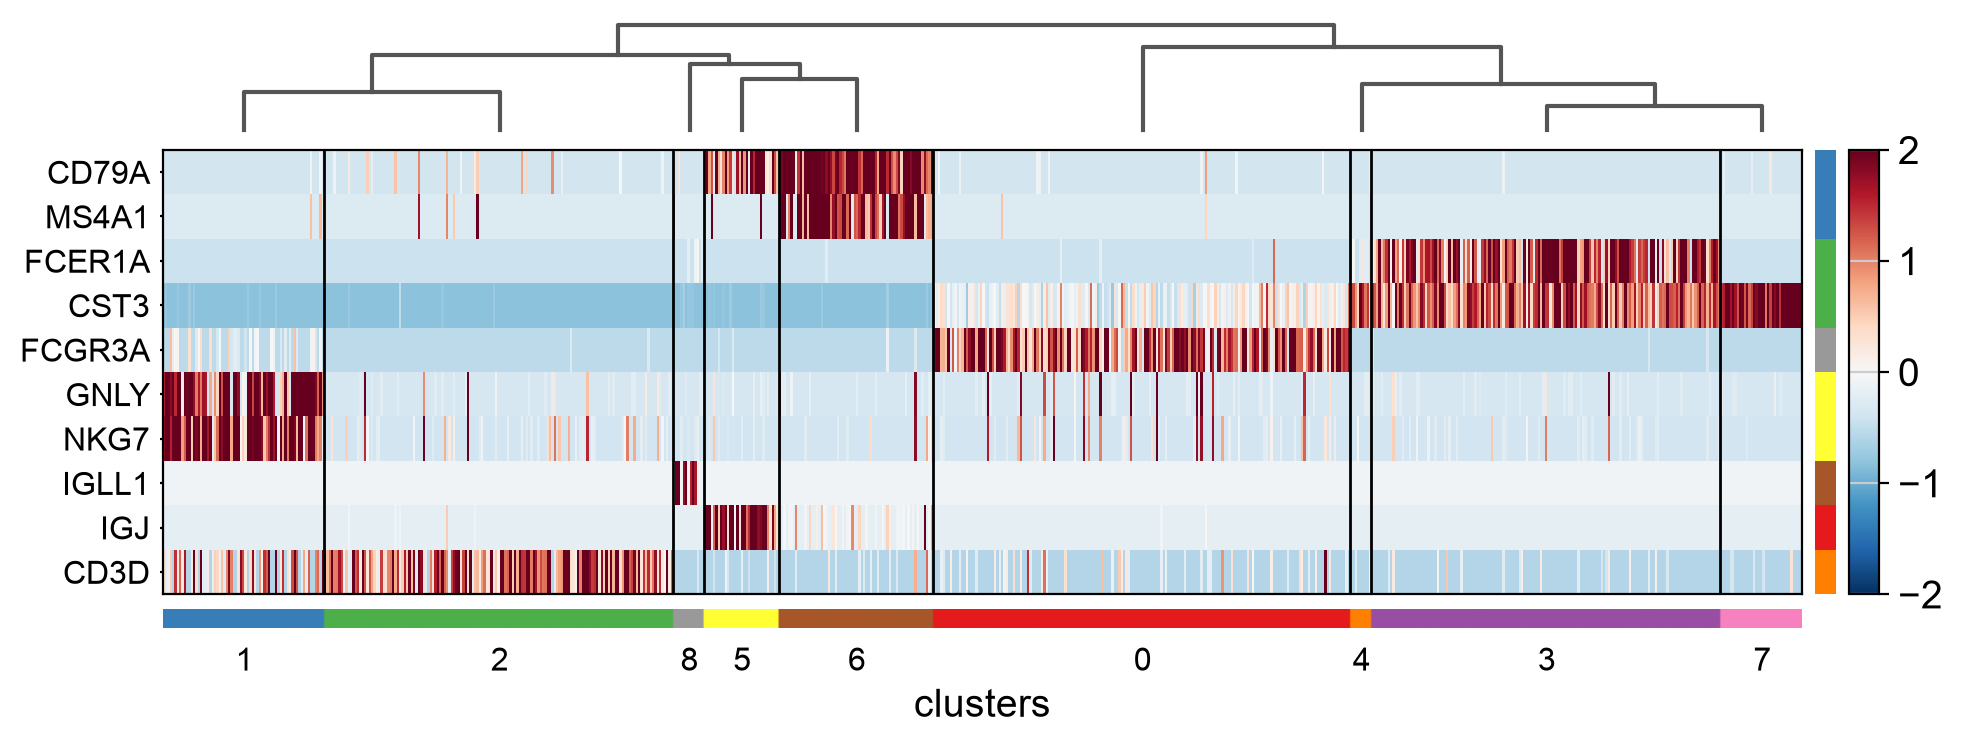

In [21]:
# heatmap on scaled data
ax = sc.pl.heatmap(
    pbmc,
    marker_genes_dict,
    groupby="clusters",
    layer="scaled",
    vmin=-2,
    vmax=2,
    cmap="RdBu_r",
    dendrogram=True,
    swap_axes=True,
    figsize=(11, 4),
)

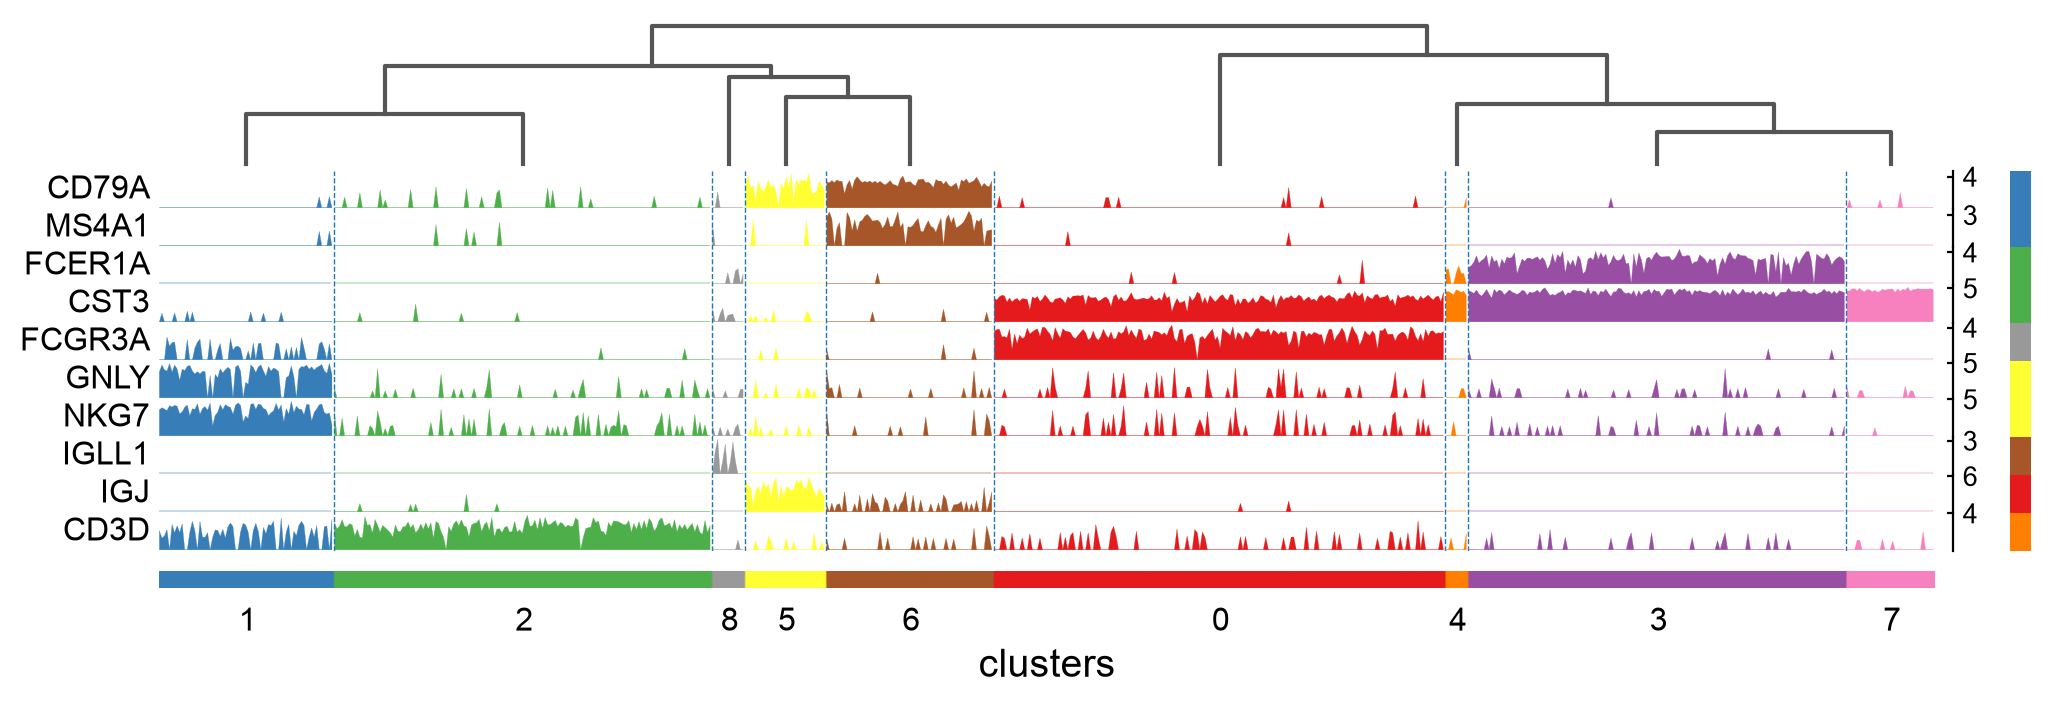

In [22]:
# Tracks plot
# per-cell information same as heatmap but shown as bar height instead of colour
# easy to see on/off pattern hard to read how many genes
sc.pl.tracksplot(pbmc, marker_genes_dict, groupby="clusters", dendrogram=True)

## Identify genes that are differentially expressed in the clusters 

Opposite to above, not from known genes, starting from differentially expressed genes in clusters. What genes make each cluster different from all the others?

In [24]:
sc.tl.rank_genes_groups(pbmc, groupby="clusters", method="wilcoxon")

# scanpy compare each cluster to all other clusters gene by gene
# wilcoxon is a rank-based test which asks whether this gene is expressed higher in this cluster than in all other clusters, and ranks genes by p-value

# make it as a table for easier viewing 
df = sc.get.rank_genes_groups_df(pbmc, group="0") # the monocyte group
df.head(10)

,names,scores,logfoldchanges,pvals,pvals_adj
0,FTL,19.892281,2.612288,4.746716e-88,3.631238e-85
1,AIF1,19.726170,4.836099,1.285501e-86,4.917040e-84
2,LST1,19.681314,4.678814,3.118050e-86,7.951027e-84
3,FCGR3A,19.665218,7.255873,4.283123e-86,8.191473e-84
4,CFD,19.130188,6.418841,1.415612e-81,2.165886e-79
5,CTSS,19.017302,3.810572,1.226337e-80,1.563580e-78
6,FCER1G,18.974379,4.207581,2.777721e-80,3.035652e-78
7,PSAP,18.944977,3.751319,4.857993e-80,4.645456e-78
8,TYROBP,18.860634,4.169687,2.403189e-79,2.042711e-77
9,TMEM176B,16.887266,6.400835,5.583053e-64,4.271036e-62


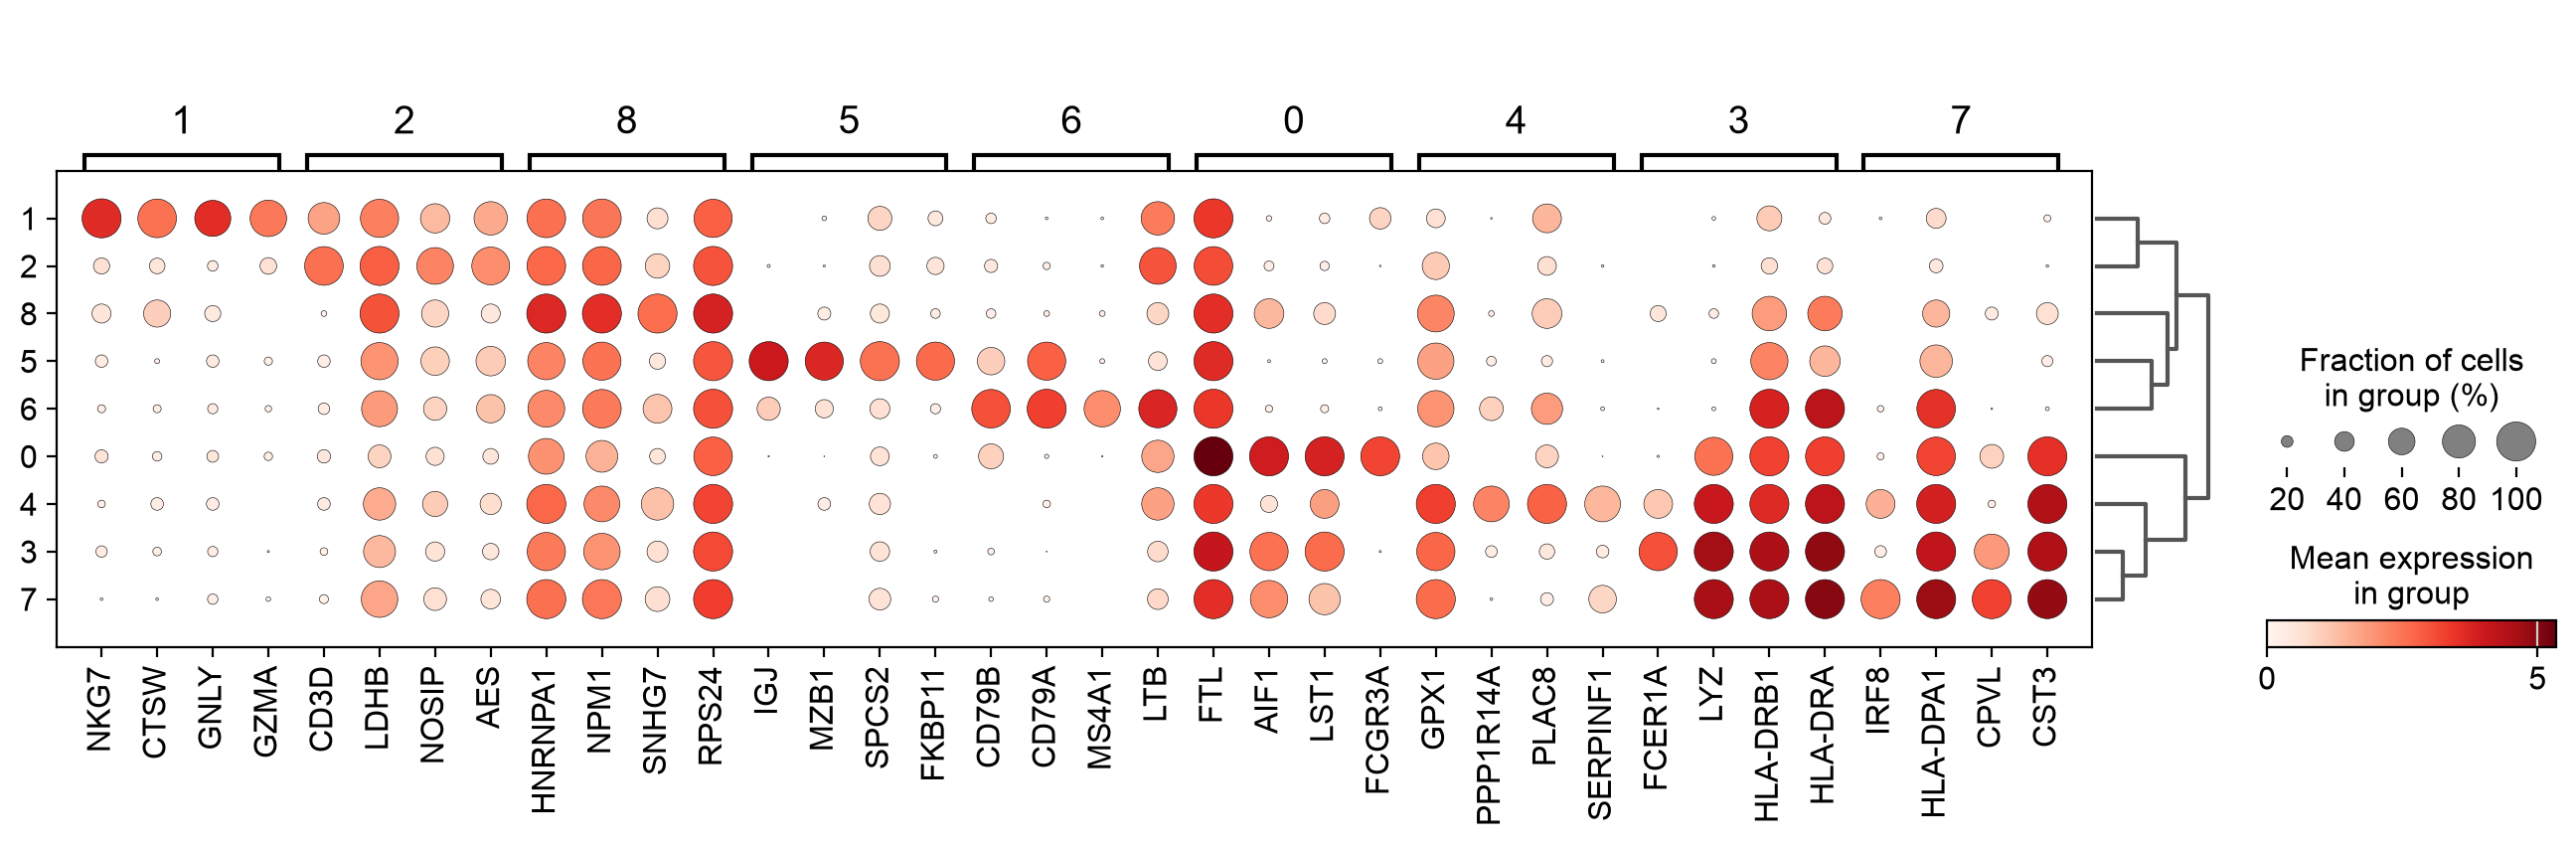

In [25]:
sc.pl.rank_genes_groups_dotplot(pbmc, n_genes=4)
# shows top 4 genes that was automatically chosen per cluster by the rank_genes_groups function, and shows how specific they are to that cluster

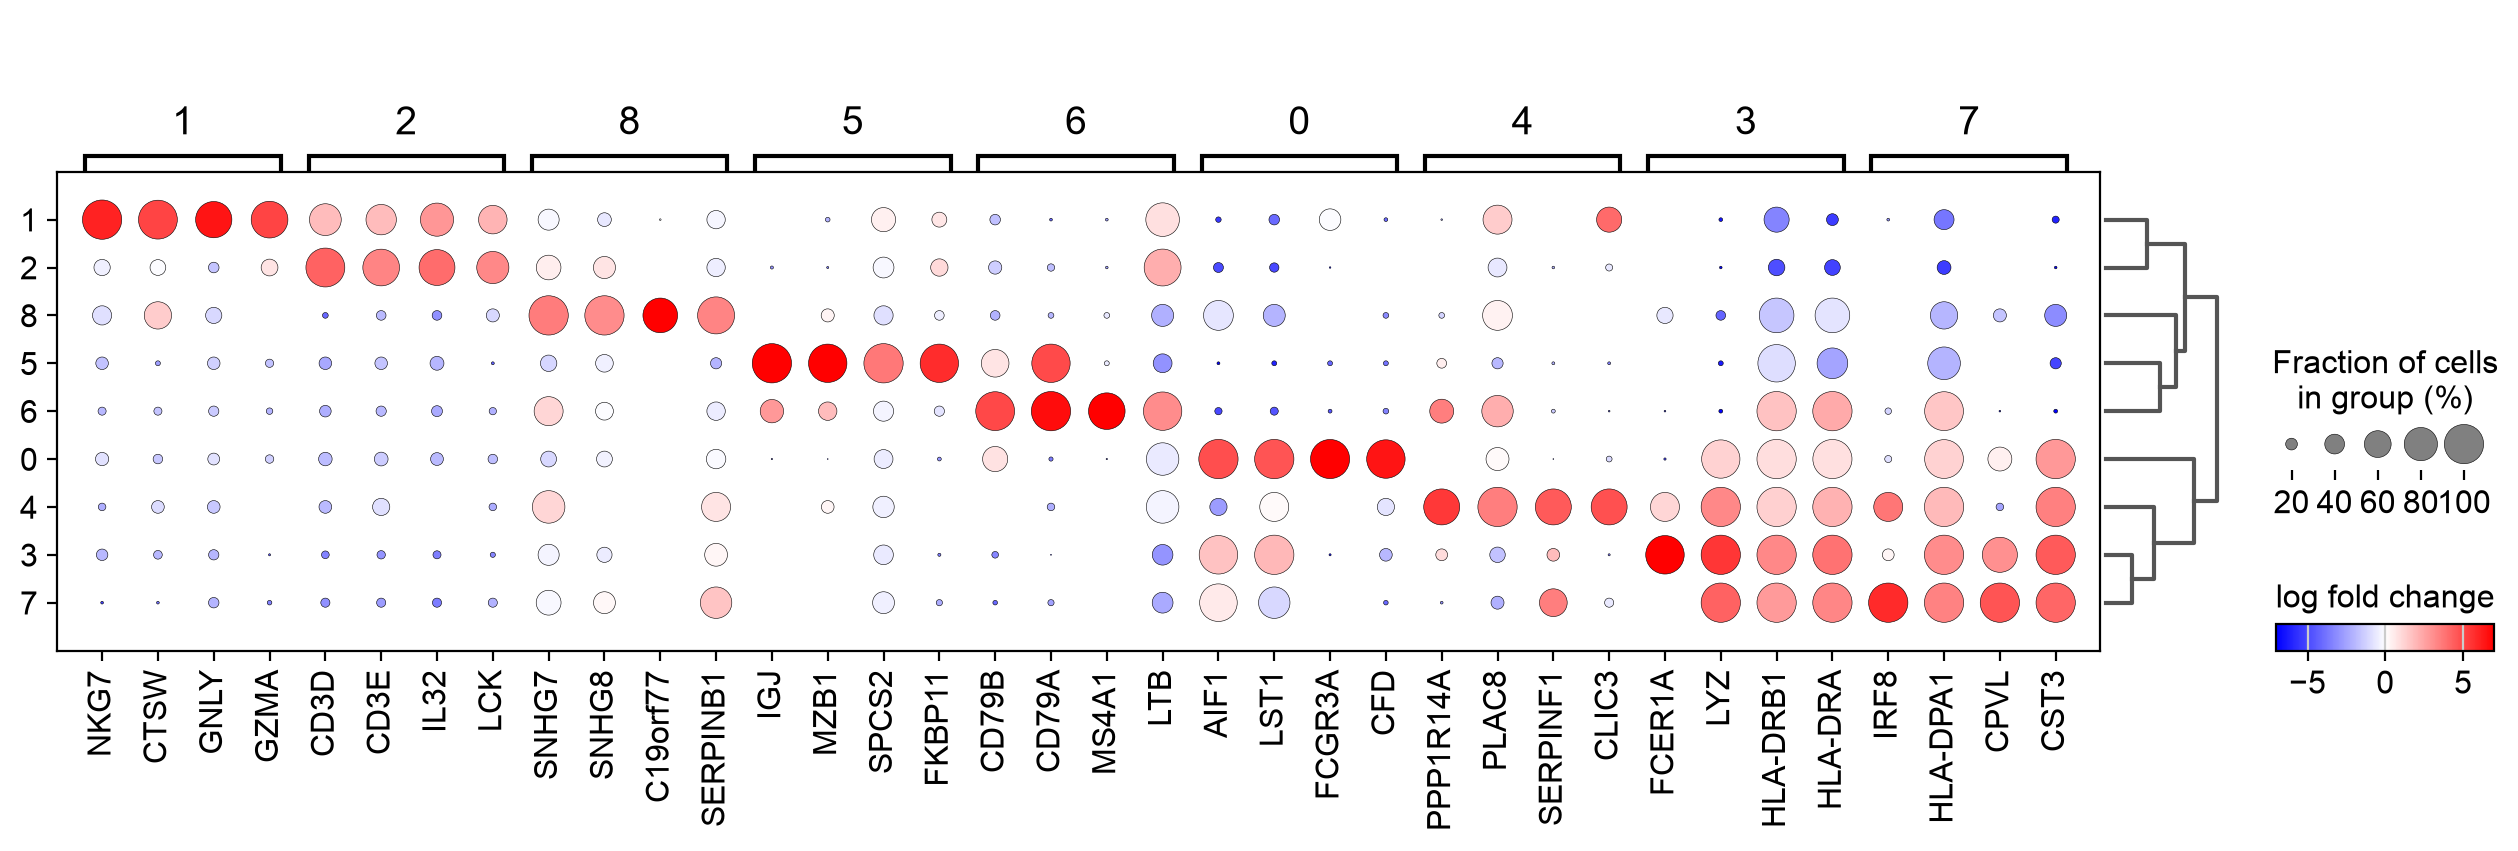

In [26]:
sc.pl.rank_genes_groups_dotplot(
    pbmc,
    n_genes=4,
    values_to_plot="logfoldchanges",
    min_logfoldchange=3,
    vmax=7,
    vmin=-7,
    cmap="bwr",
)

# log fold change is how many times higher the expression of that gene is in that cluster compared to all other clusters
# min_logfoldchange=3 means only show genes strong difference
# T cell subtypes (CD4, CD8) hard ti distinguish as they shares many common genes
# this one vs rest helps to find few strong unique markers

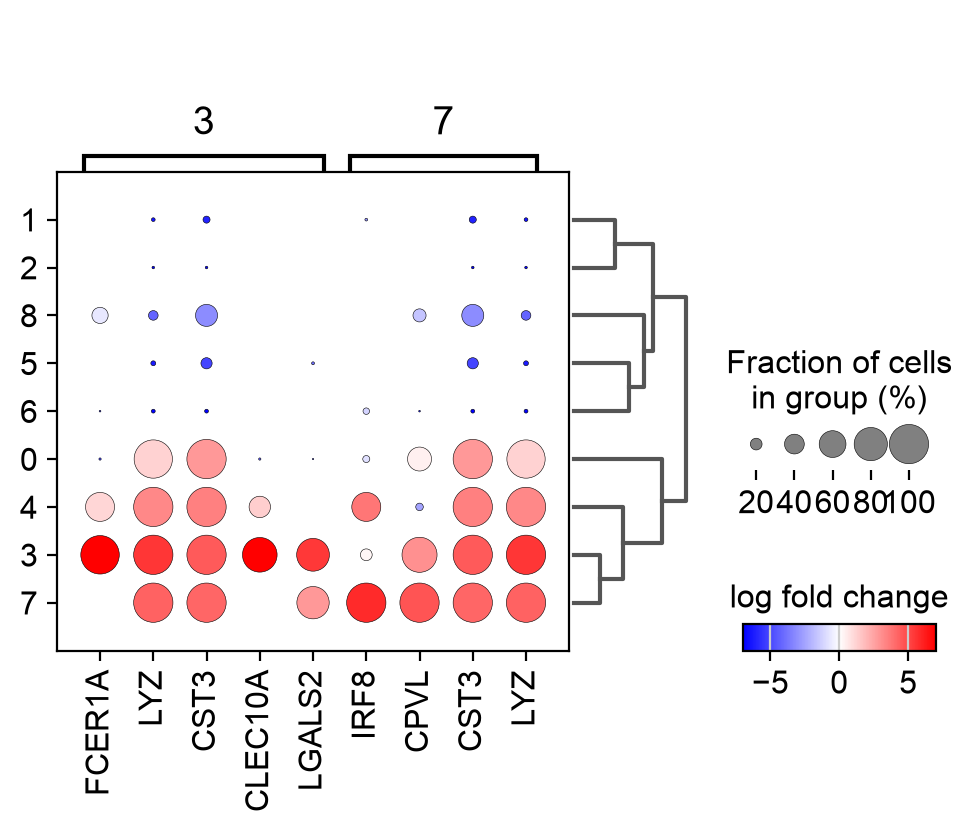

In [27]:
# focusing on particular groups
sc.pl.rank_genes_groups_dotplot(
    pbmc,
    n_genes=30,
    values_to_plot="logfoldchanges",
    min_logfoldchange=4,
    vmax=7,
    vmin=-7,
    cmap="bwr",
    groups=["3", "7"],
)

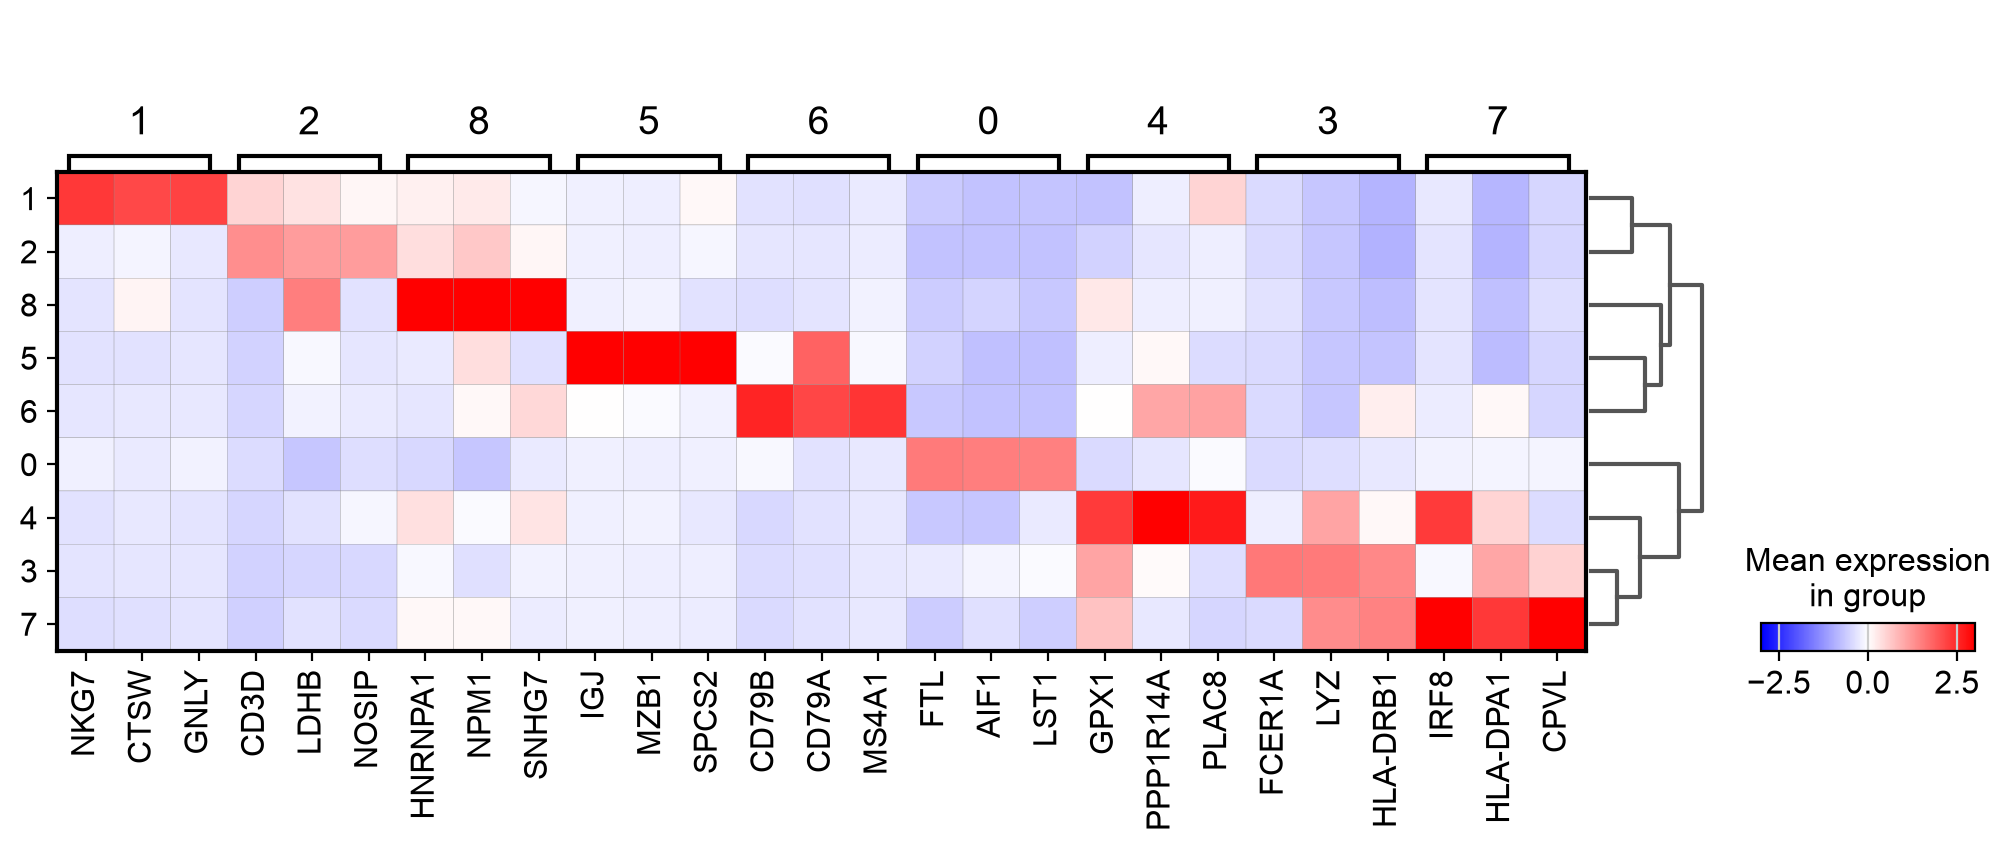

In [28]:
#visualize marker genes using matrixplot
sc.pl.rank_genes_groups_matrixplot(pbmc, n_genes=3, use_raw=False, vmin=-3, vmax=3, cmap="bwr", layer="scaled")

# matrixplot shows mean z-score of each gene in that cluster, and shows how specific they are to that cluster

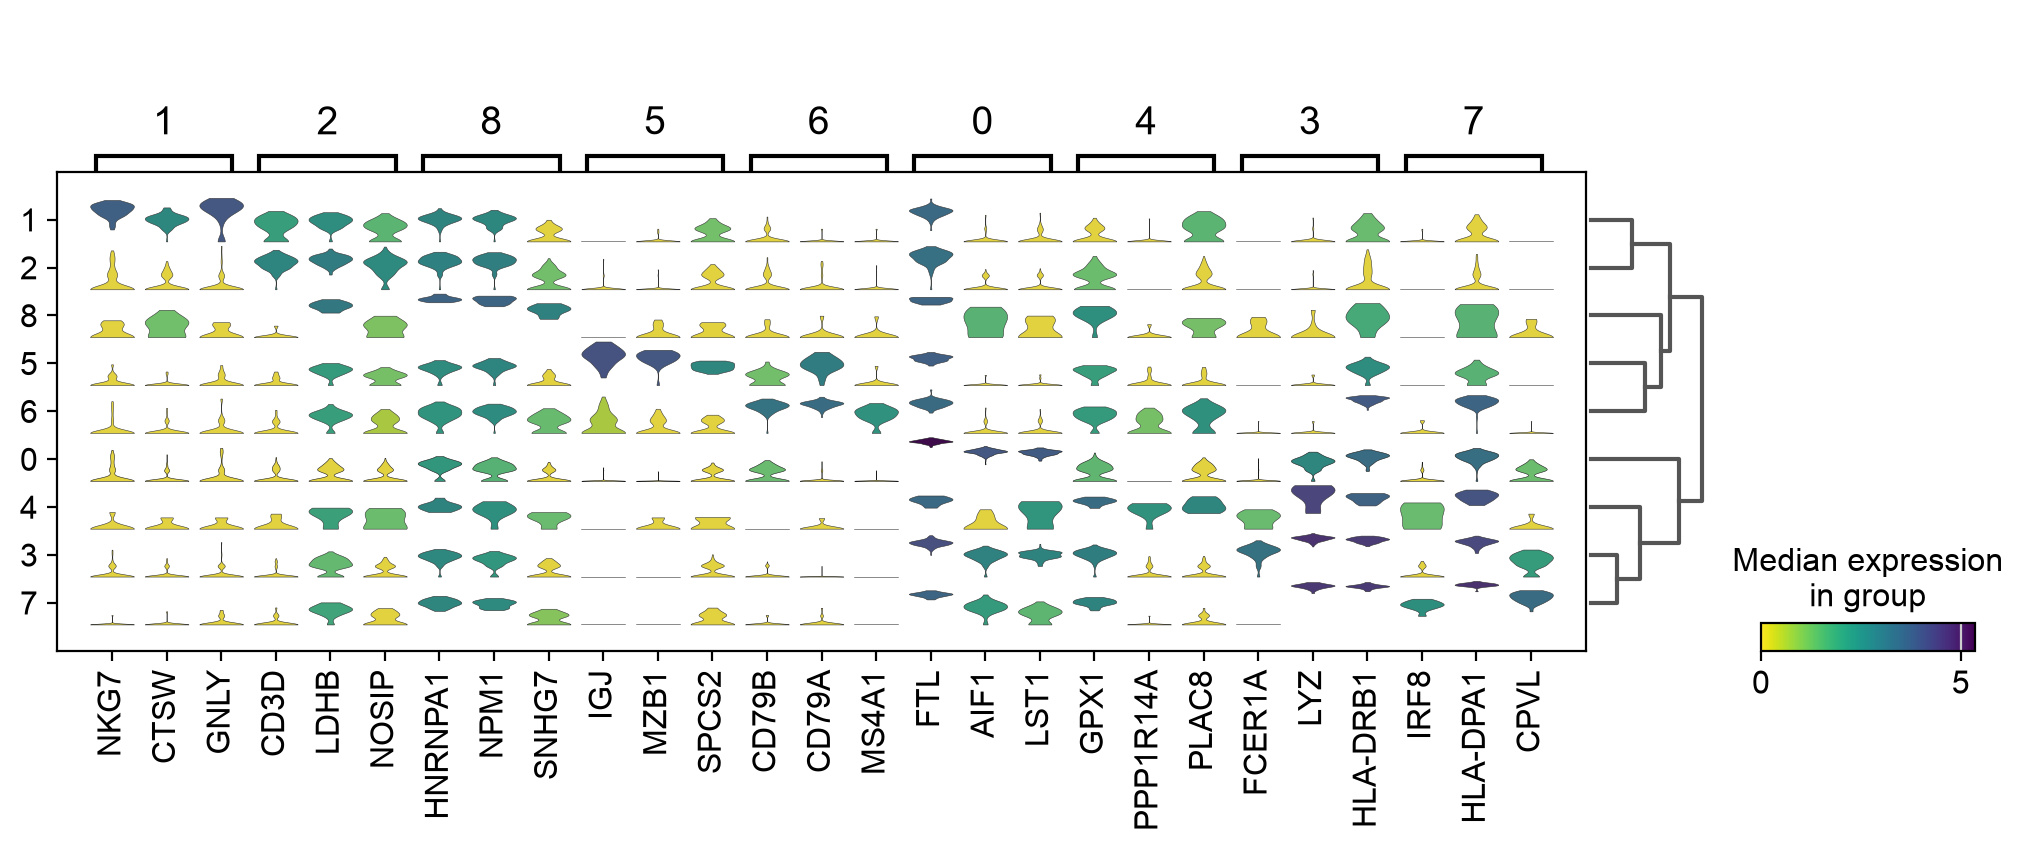

In [31]:
# Visualize marker genes using stacked violin plots
sc.pl.rank_genes_groups_stacked_violin(pbmc, n_genes=3, cmap="viridis_r", dodge=False)

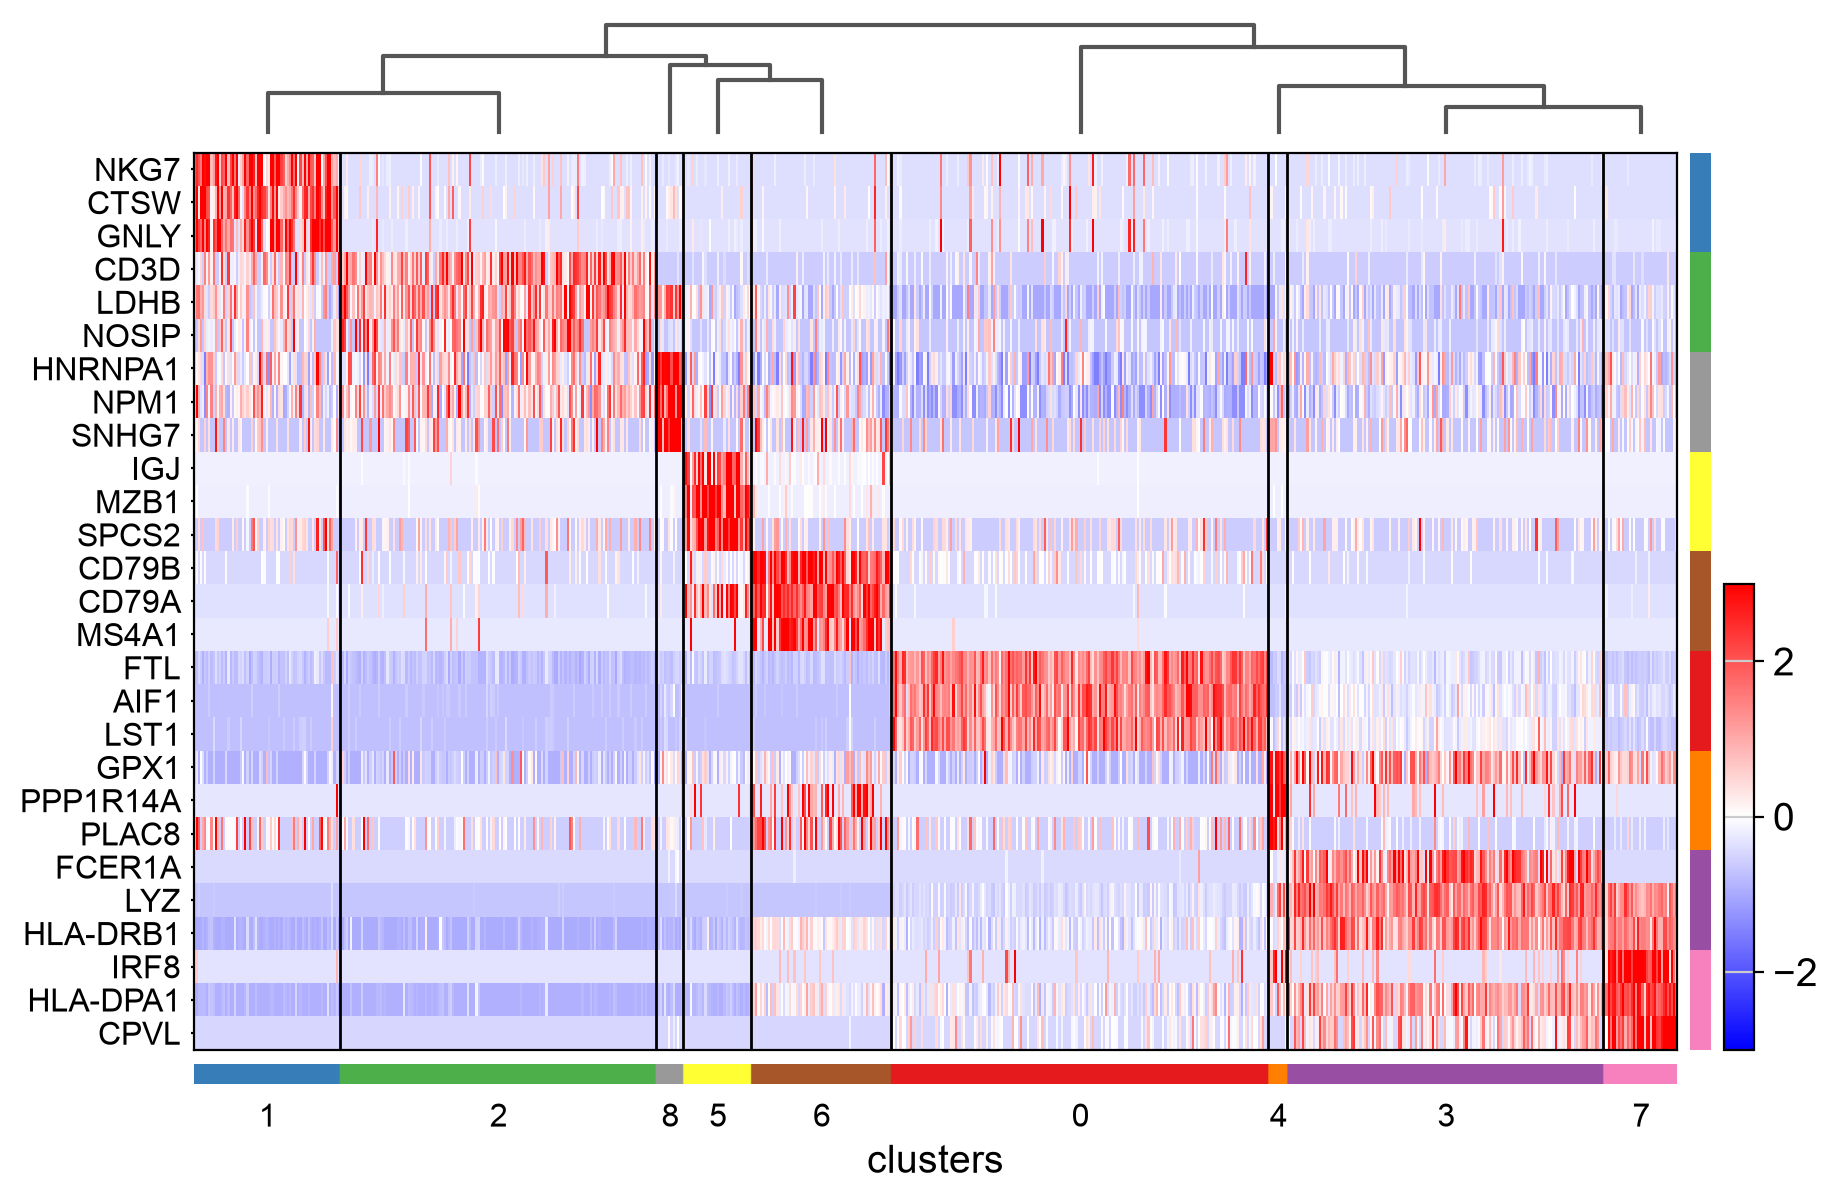

In [30]:
# Visualize marker genes using heatmap
sc.pl.rank_genes_groups_heatmap(
    pbmc,
    n_genes=3,
    use_raw=False,
    swap_axes=True,
    vmin=-3,
    vmax=3,
    cmap="bwr",
    layer="scaled",
    figsize=(10, 7),
    show=False,
);

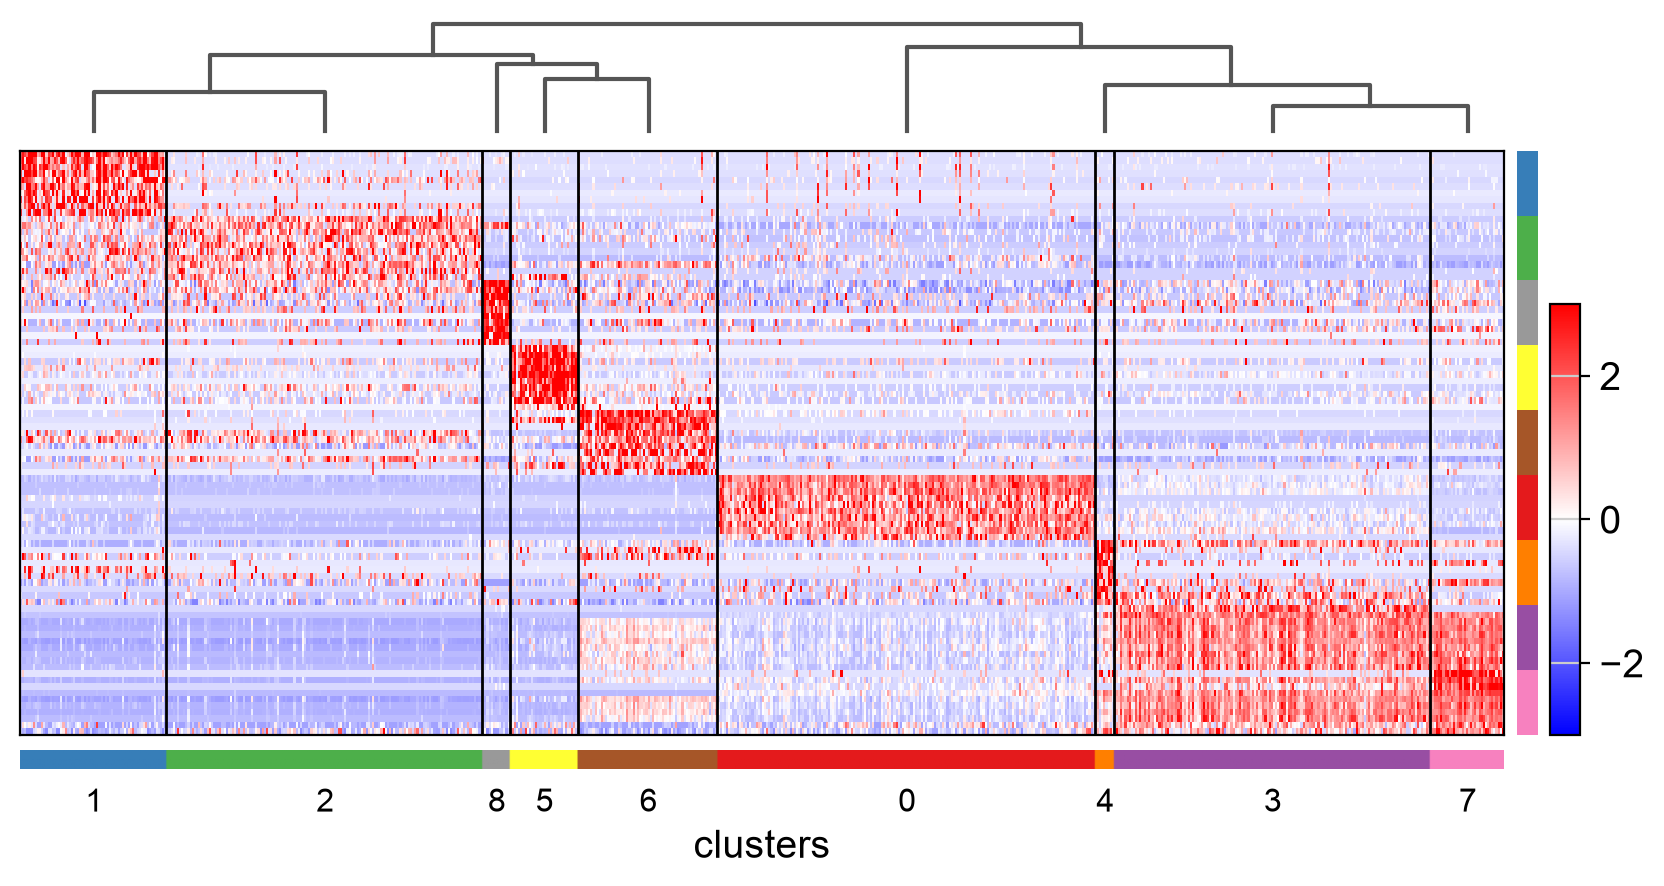

In [ ]:
sc.pl.rank_genes_groups_heatmap(
    pbmc,
    n_genes=10, # with top 10 automatically chosen genes per cluster
    use_raw=False,
    swap_axes=True,
    show_gene_labels=False,
    vmin=-3,
    vmax=3,
    cmap="bwr",
)

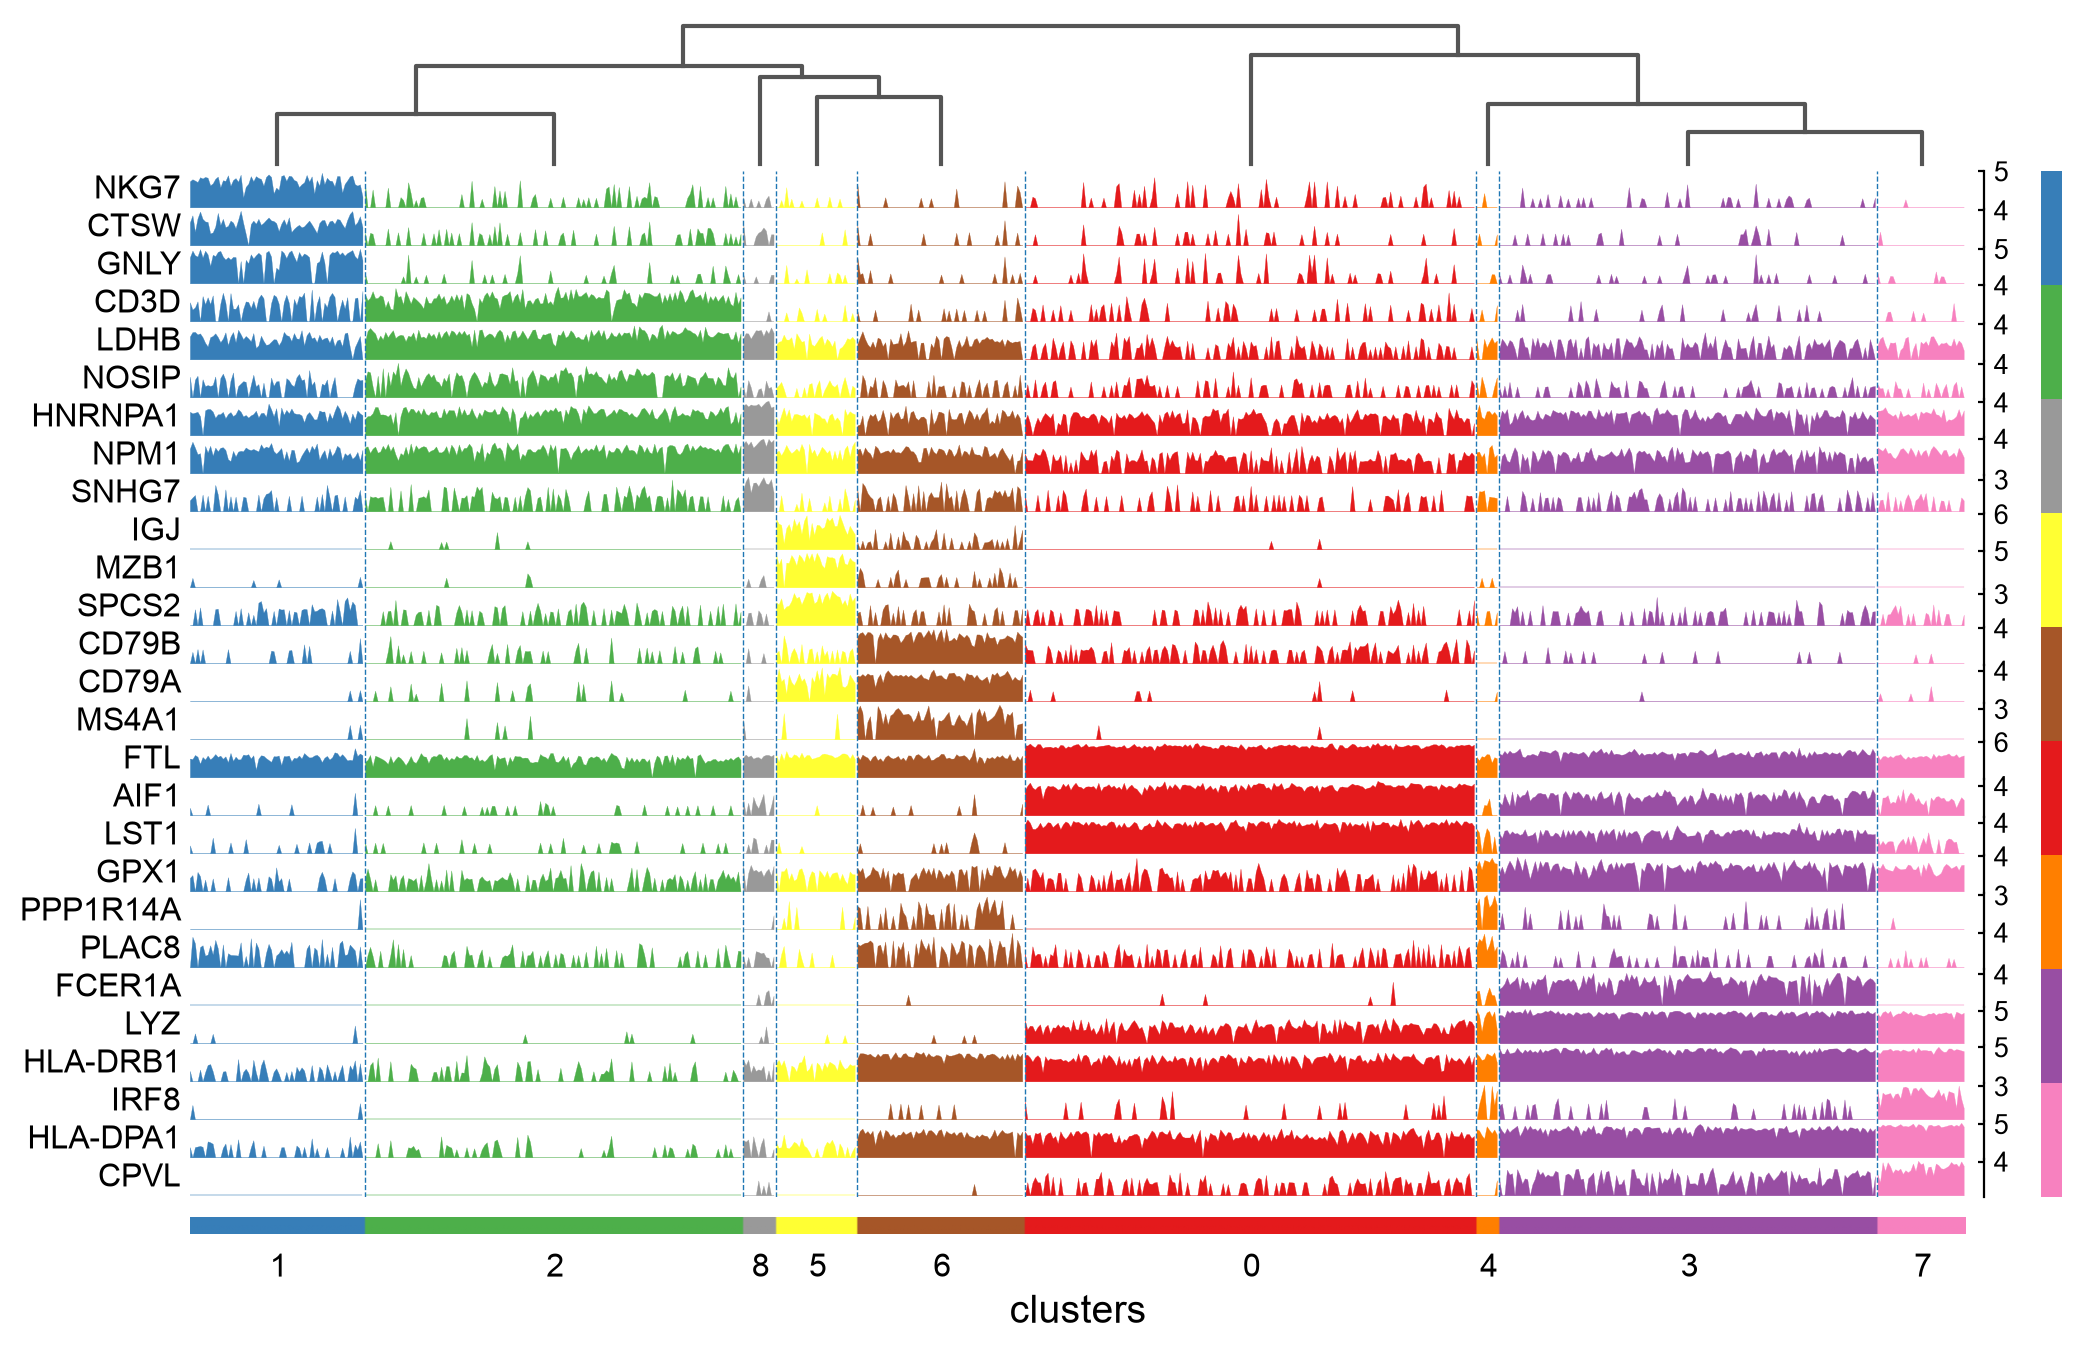

In [33]:
# Visualize marker genes using tracksplot 
sc.pl.rank_genes_groups_tracksplot(pbmc, n_genes=3)

## Differences of each plot type summary
- Matrixplot: mean z-scores 
- Stacked violin: distribution of the top 3 genes per cluster
- Heatmap: per cell activity, show_gene_labels = False and 10 genes per cluster will give clean block diagonal which represent well separation of the clusters
- Tracksplot: per cell activity with height instead of colour


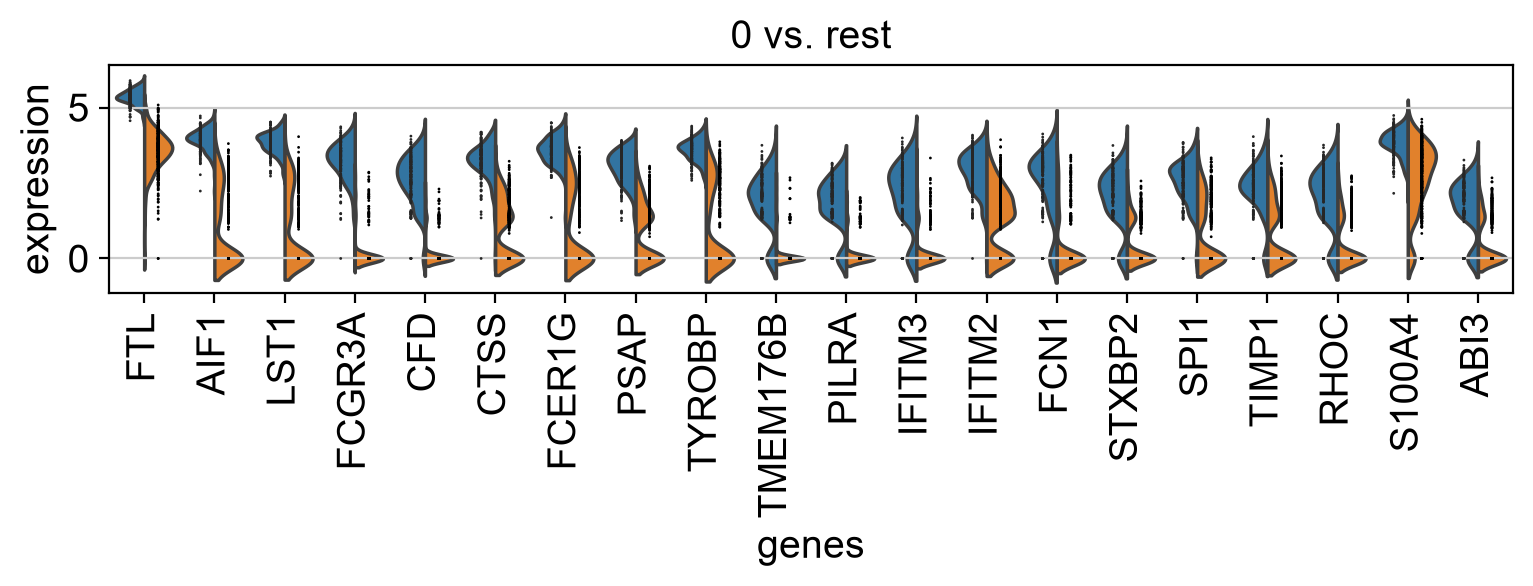

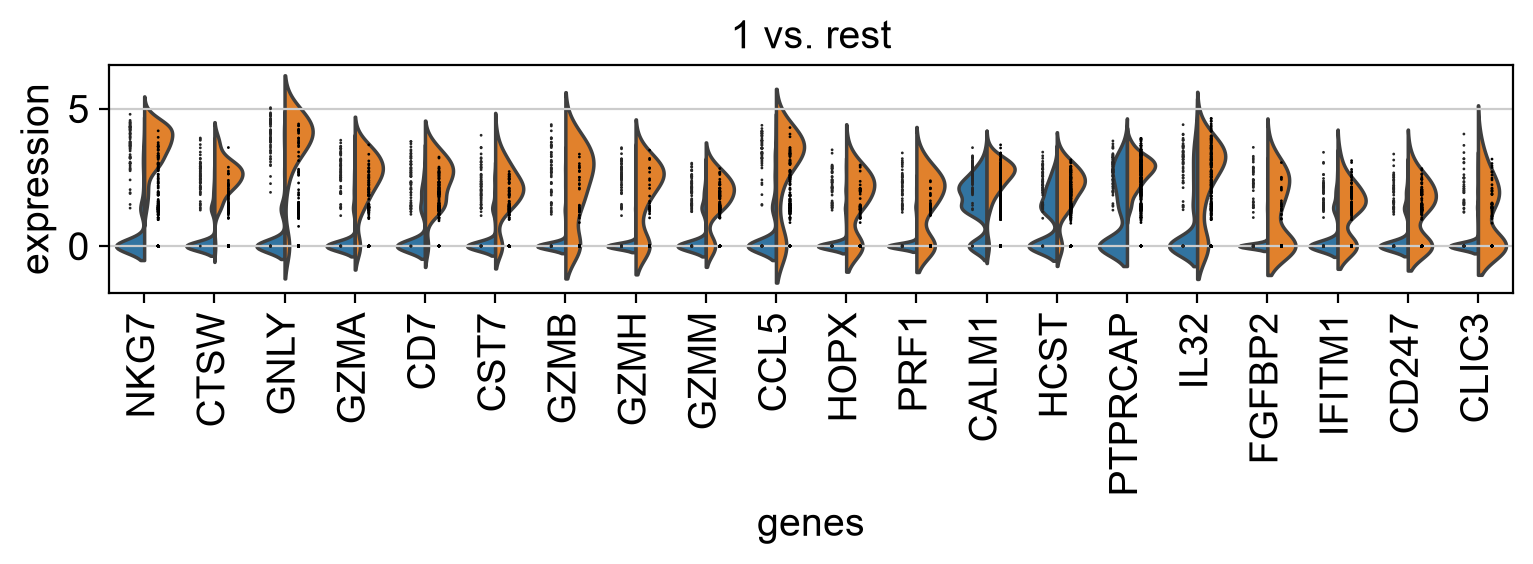

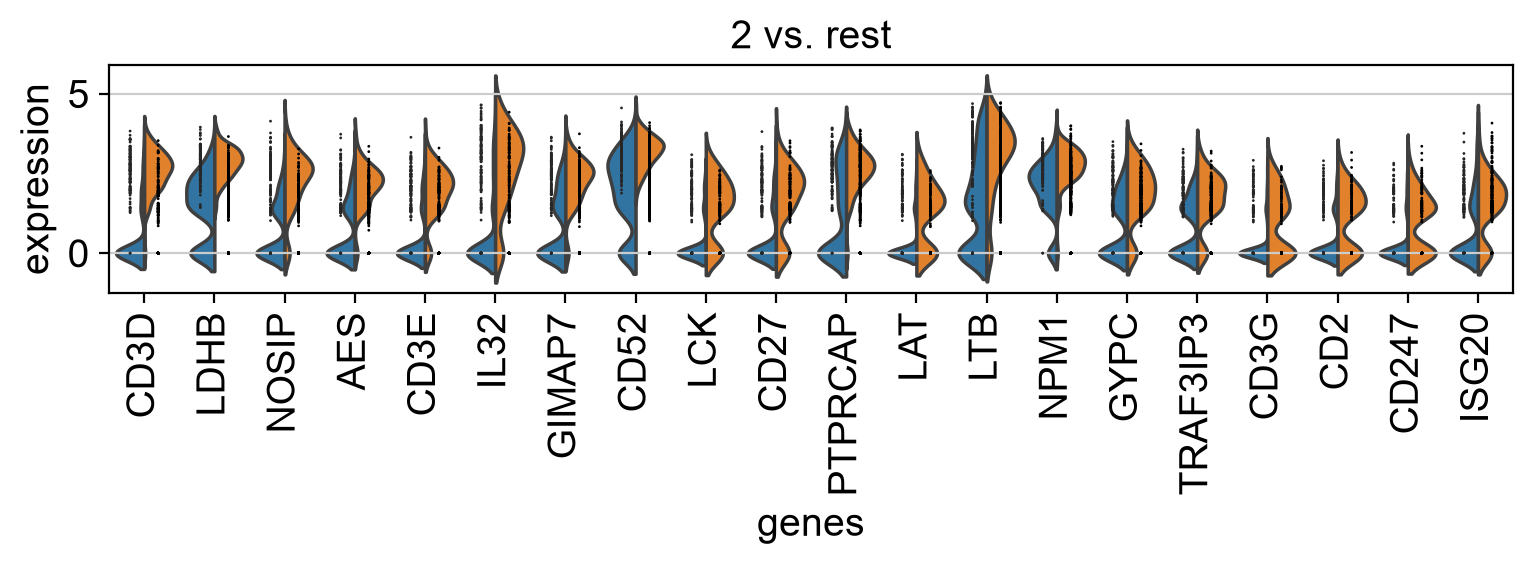

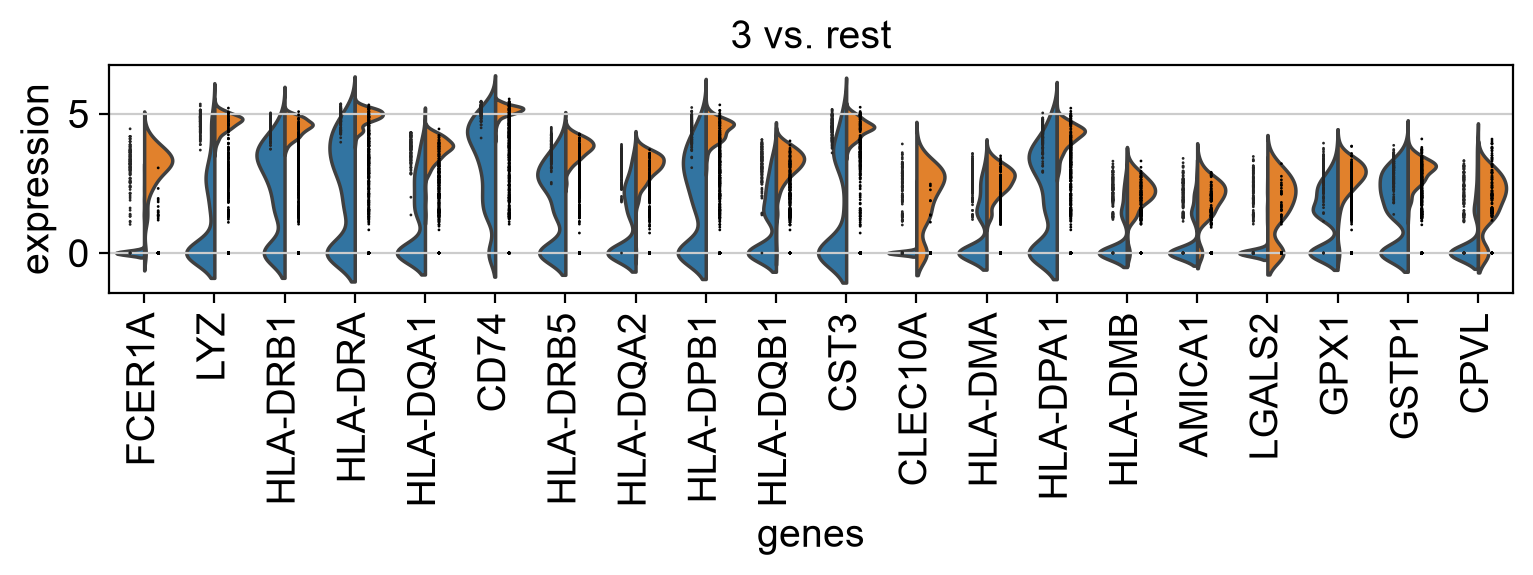

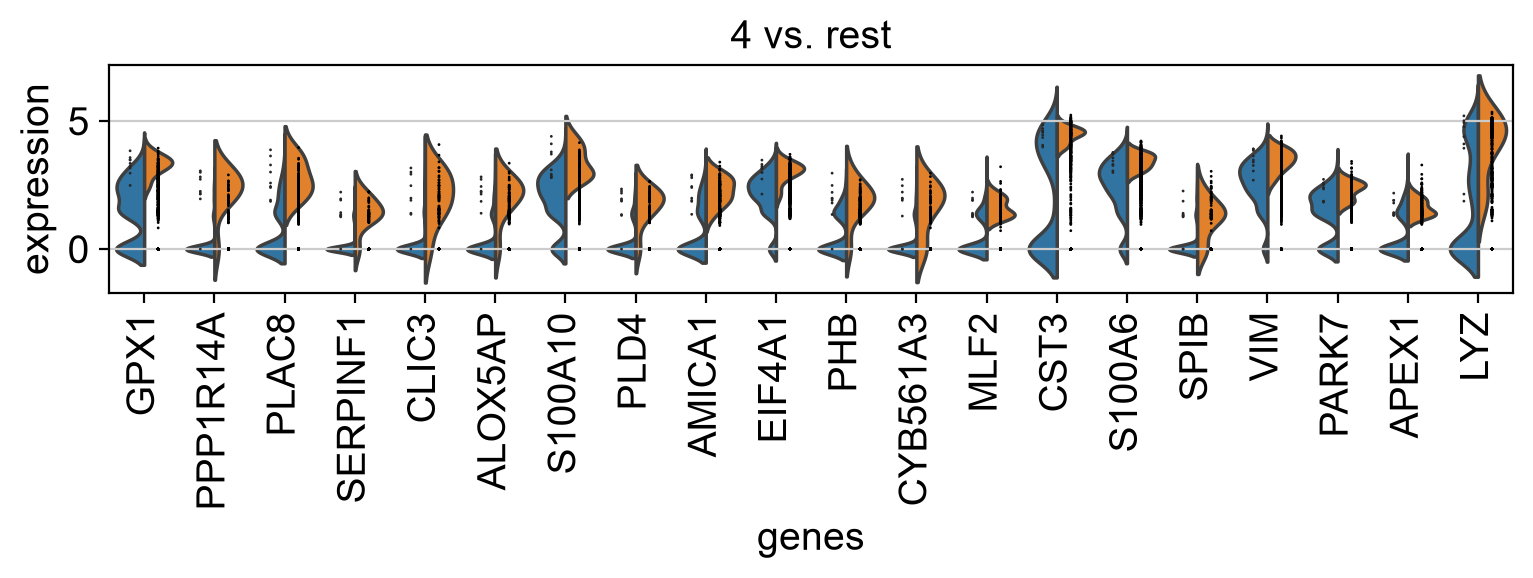

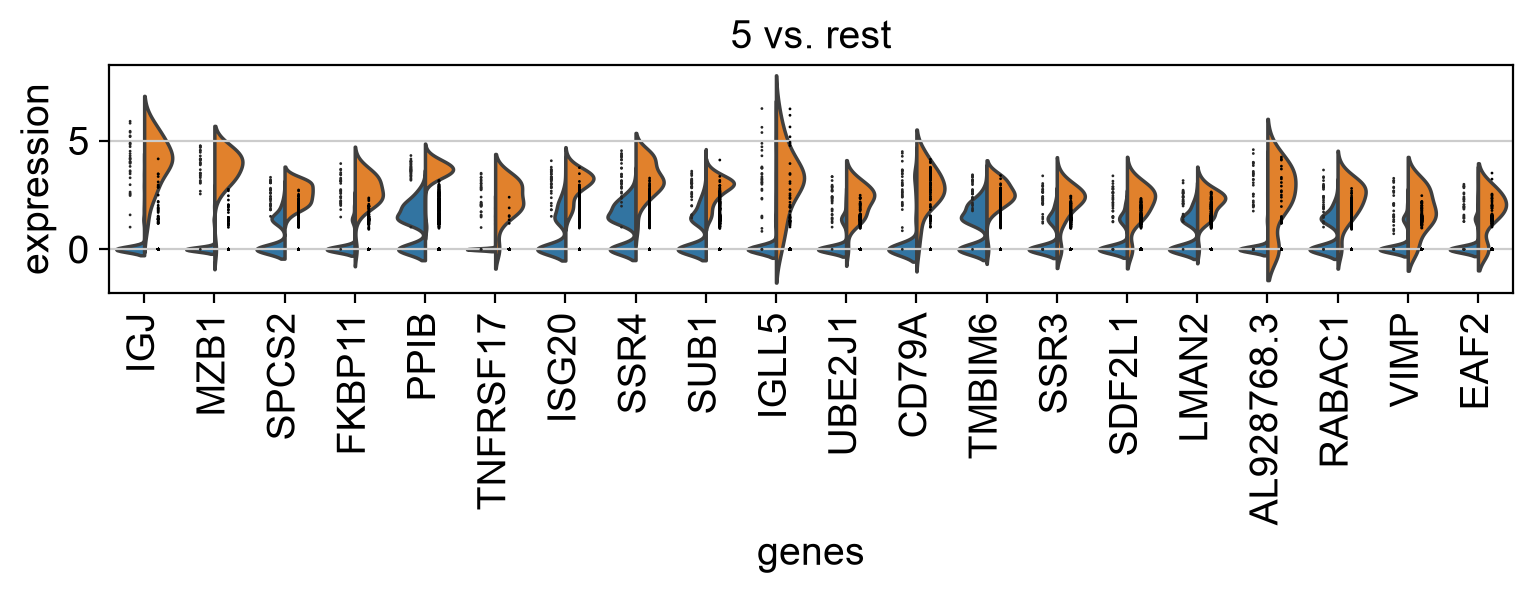

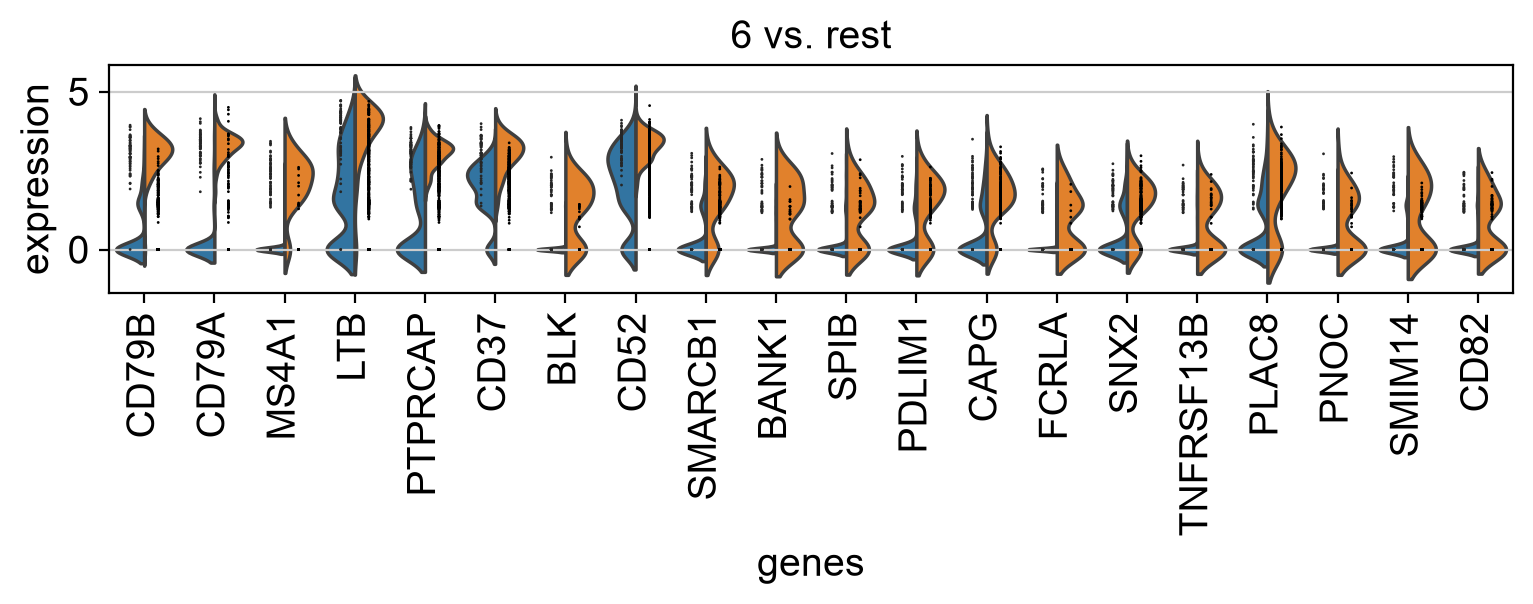

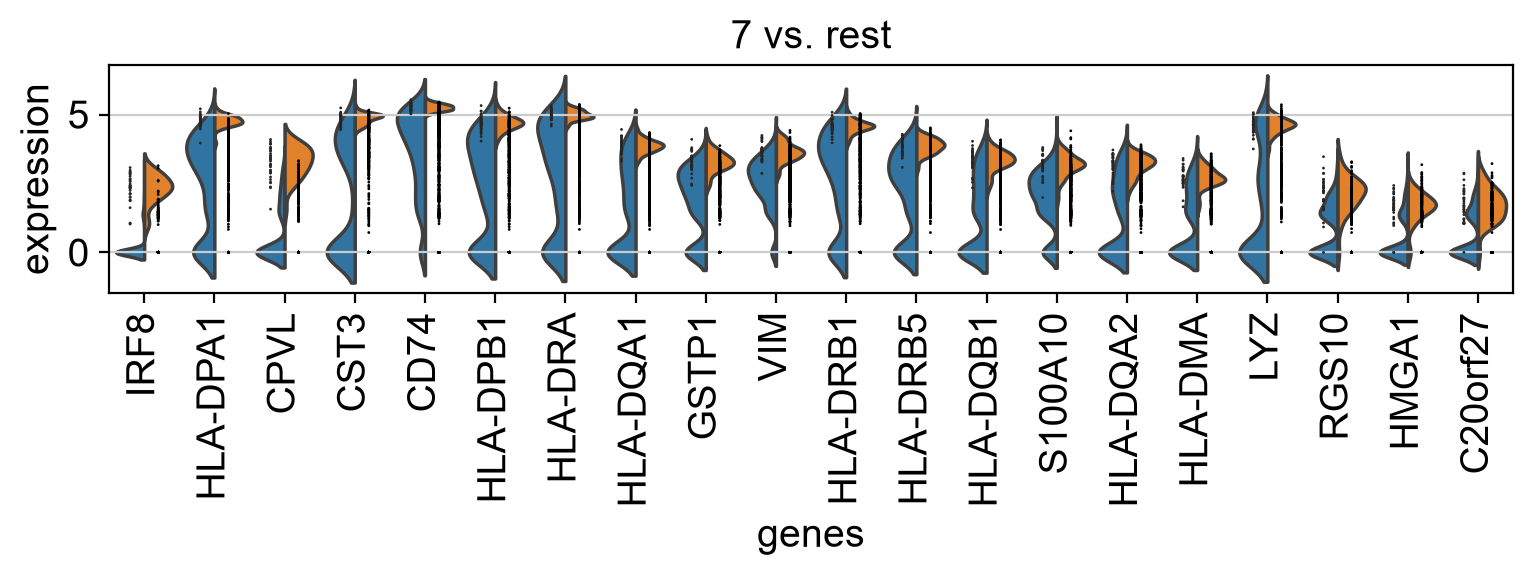

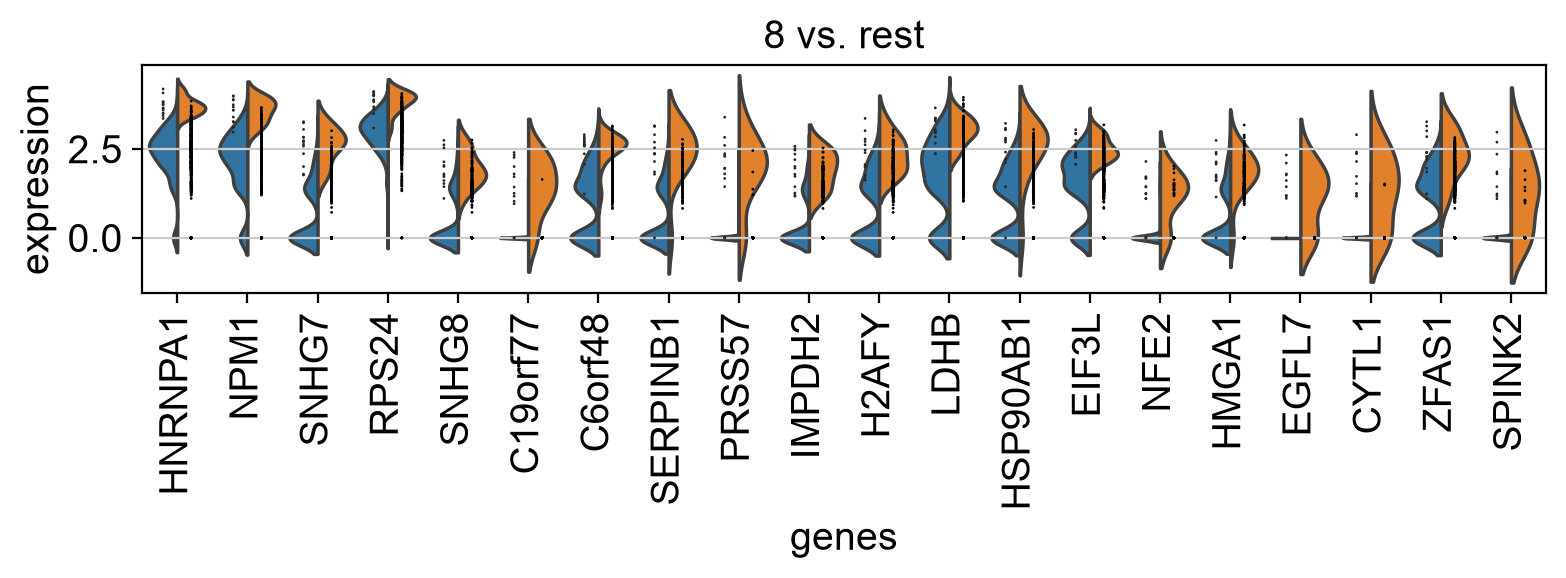

In [ ]:
# split violin plots one vs rest for every cluster, showing the top 20 genes per cluster
with rc_context({"figure.figsize": (9, 1.5)}):
    sc.pl.rank_genes_groups_violin(pbmc, n_genes=20, jitter=False)

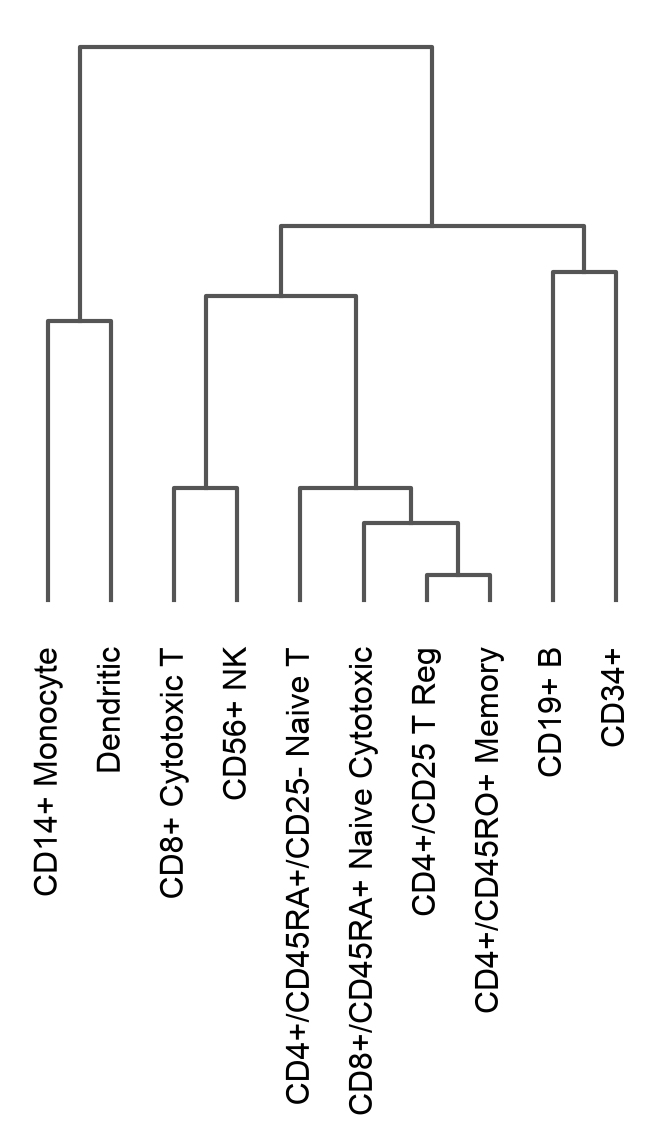

In [38]:
# Plotting dendrogram independently
# compute hierarchical clustering using PCs (several distance metrics and linkage methods are available).
sc.tl.dendrogram(pbmc, "bulk_labels")
ax = sc.pl.dendrogram(pbmc, "bulk_labels")

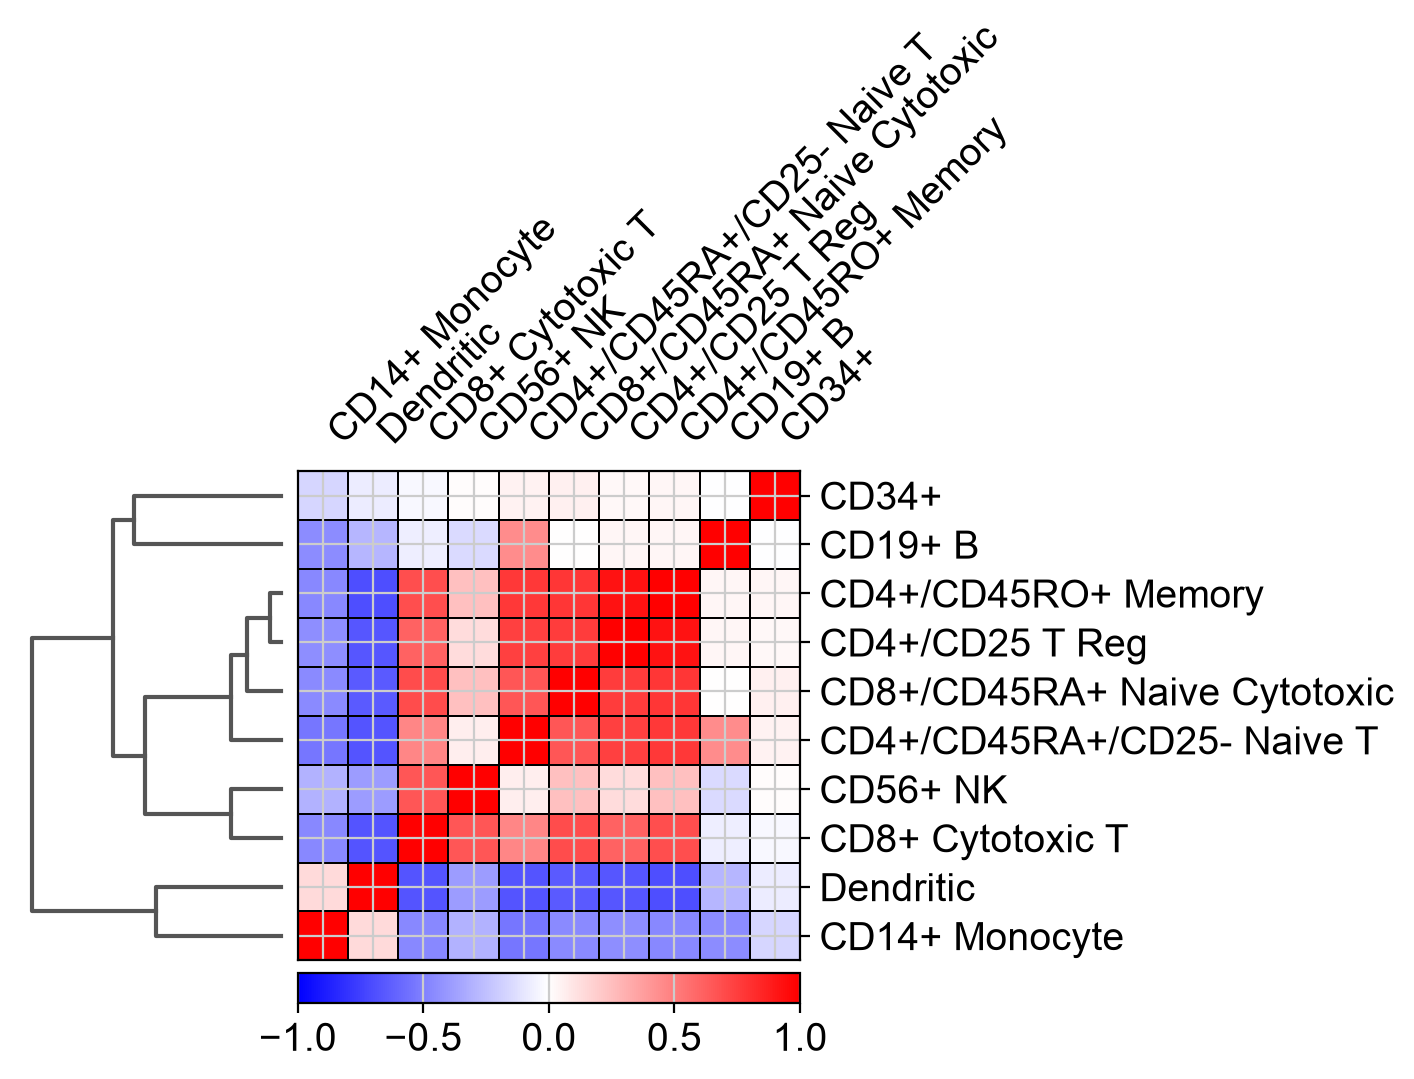

In [39]:
# plot correlation
# higher number of PCs used for clustering, the more similar clusters will be to each other
ax = sc.pl.correlation_matrix(pbmc, "bulk_labels", figsize=(5, 3.5))

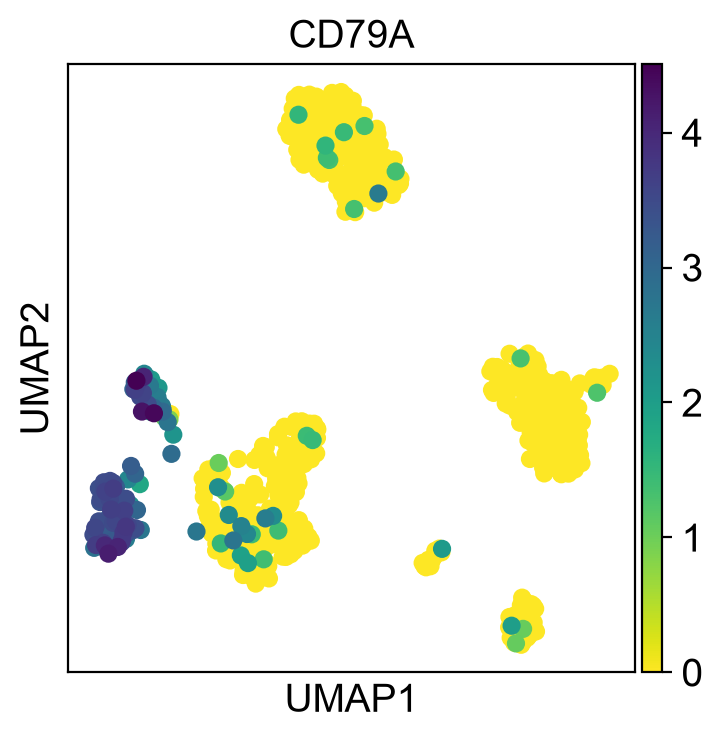

In [40]:
# saving plots
sc.pl.umap(pbmc, color="CD79A", show=False).figure.savefig("CD79A.png")